In [1]:
from app.services.entities import Passenger, Interval, Flight, ArrivalSampler
import app.services.predictive as predictive
import app.services.preprocessing as preprocessing
import app.services.samplers as samplers
import app.services.arrival_flow as arrival_flow
import app.services.security_class as security_class
import app.services.utils as utils
from app.services.coverage_dp import coverage_report, solve_coverage_batch, allocate_budget, solve_allocated
import app.services.plotting_utils as plotutils

# import app.services.simulation as simulation
# import app.services.metrics as metrics



# from app.compute_service.domain.flight_demand import build_flight_demand
import joblib
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import ast
import json
import requests
import asyncio
from io import BytesIO, StringIO
base_seed = 42

import logging
logging.basicConfig(level=logging.INFO, 
                    format="%(asctime)s | %(levelname)s | %(name)s | %(message)s",
                    force=True)

### ML

In [5]:
apt_iata = "FLR"
folder = os.path.join("data", "hist_schedule")

files = [
    os.path.join(folder, f)
    for f in os.listdir(folder)
    if f.endswith(".csv")
]

df = pd.concat(
    [pd.read_csv(file, sep=';', low_memory=False) for file in files],
    ignore_index=True
)

#filter schedule
df_f = df[(df['AVIAZIONE'] == 'Commerciale') & (df['NATURA'] == 'P') & (df['SCALO_TECNICO'] == 0) & (df['ADULT'] != 0) & (~df['NUMERO_MASSIMO_PAX'].isna()) & 
          ((df['ADULT']+df['CHILD']) <= df['NUMERO_MASSIMO_PAX'])]

df_f

,ID_VOLO,ID_LEGATO,DATA_VOLO,NOME_ESERCENTE,NAME_CARRIER,MATRICOLA_AEROMOBILE,PESO_MASSIMO,MODELLO_AEROMOBILE,NUMERO_MASSIMO_PAX,CODICE_ICAO,...,CERTIFICATO,ESPORTATO,GATE,VOLO_RISCHEDULATO,STATO_ATTIVITA,READY,CERT_TIMESTAMP,DATA_DIR_CANC,CAUSALE_DIR_CANC,MERCE_ESENTE
29,26808735,26808210.0,20170101,NaN,AIR FRANCE,FGUGI,60.0,A318,131.0,AFR,...,S,S,NaN,NaN,Completato,NaN,2017-01-02 08:56:31.000,NaN,NaN,NaN
30,26808742,26808231.0,20170101,NaN,KLM-ROYAL DUTCH AIRLINES,PHEZO,45.0,E190,100.0,KLM,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 07:11:01.000,NaN,NaN,NaN
31,26808756,26808217.0,20170101,NaN,LUFTHANSA,DAECD,51.0,E190,94.0,DLH,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 08:24:24.000,NaN,NaN,NaN
32,26808763,26808196.0,20170101,NaN,VUELING AIRLINES,ECMKV,64.0,A319,144.0,VLG,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 09:31:49.000,NaN,NaN,NaN
33,26808770,26808189.0,20170101,NaN,SWISS,HBJVP,51.0,E190,110.0,SWR,...,S,S,NaN,NaN,Completato,NaN,2017-01-01 10:52:52.000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,68716698,68716533.0,20251218,NaN,ITA AIRWAYS,EIIMB,64.0,A319,144.0,ITY,...,S,S,GATE 1,NaN,Completato,NaN,2026-01-05 10:55:26.000,NaN,NaN,0.0
314427,68924169,68923996.0,20251208,NaN,AIR SERBIA,YUAPF,68.0,A319,144.0,ASL,...,S,S,GATE 11,NaN,Completato,NaN,2025-12-08 21:27:43.000,NaN,NaN,0.0
314477,69100636,64538481.0,20251205,NaN,VOLOTEA,ECNGL,66.0,A319,156.0,VOE,...,S,S,GATE 2,NaN,Completato,NaN,2025-12-09 08:57:58.000,NaN,NaN,0.0
314736,69688892,64545032.0,20251217,NaN,AIR FRANCE,FHZUX,64.0,BCS3,148.0,AFR,...,S,S,GATE 3,NaN,Completato,NaN,2025-12-17 12:40:04.000,NaN,NaN,0.0


In [6]:
def standardize_df(df):
    df=df.copy()

    col_mapping= {'DATA_PREVISTA': 'date', 'ORA_PREVISTA': 'schtime', 
                  'CODICE_IATA':'car', 'CODICE_ICAO': 'car_icao', 'NUMERO_VOLO': 'flt_n', 'DESTINAZIONE': 'apt', 
                  'MODELLO_AEROMOBILE': 'ac', 'NUMERO_MASSIMO_PAX':'seats', 'ADULT': 'adults', 'CHILD': 'children', 'NUM_BAGAGLI': 'luggage'}
    df = df[col_mapping.keys()].copy()
    df.rename(columns=col_mapping, inplace=True)

    df["date"] = pd.to_datetime(df["date"].astype("string"), format="%Y%m%d", errors="coerce")

    df['week_day']= df['date'].dt.day_name(locale='en_US')
    df['month'] = df['date'].dt.month_name(locale='en_US')
    df['year'] = df['date'].dt.year

    schtime = (
        df["schtime"]
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.zfill(4)
    )

    schtime_dt = pd.to_datetime(
        schtime,
        format="%H%M",
        errors="coerce"
    )

    df["schtime"] = schtime_dt.dt.strftime("%H:%M")

    hour_decimal = schtime_dt.dt.hour + schtime_dt.dt.minute / 60

    df["sin_hour"] = np.sin(2 * np.pi * hour_decimal / 24)
    df["cos_hour"] = np.cos(2 * np.pi * hour_decimal / 24)

    df["fdatetime"] = pd.to_datetime(
        df["date"].dt.strftime("%Y-%m-%d")
        + " "
        + df["schtime"],
        errors="coerce"
    )

    # Carrier code
    df["car"] = (
        df["car"]
        .fillna(df["car_icao"])
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df = df[df["car"] != "_"].copy()

    # Flight number
    df["flt_n"] = (
        df["flt_n"]
        .fillna("")
        .astype("string")
        .str.replace(".0", "", regex=False)
        .str.strip()
        .str.replace(" ", "", regex=False)
        .str.upper()
        .str.replace(r"^0+(?=.)", "", regex=True)
    )

    # nflt = carrier + flight number, con uno spazio
    df["nflt"] = df["car"] + " " + df["flt_n"]
    df.drop(columns=["car_icao", 'flt_n'], inplace=True)

    df["ac"] = (
        df["ac"]
        .fillna("_")
        .astype("string")
        .str.strip()
        .str.upper()
        .replace("", "_")
    )

    df['pax'] = df['adults'] + df['children']
    df["load_factor"] = df["pax"] / df["seats"]

    return df

df1 = standardize_df(df_f)
# remove covid years
df1 = df1[~df1['year'].isin([2020, 2021])].copy()
print(df1.shape)
df1

(102722, 18)


,date,schtime,car,apt,ac,seats,adults,children,luggage,week_day,month,year,sin_hour,cos_hour,fdatetime,nflt,pax,load_factor
29,2017-01-01,06:20,AF,CDG,A318,131.0,115,10,101,Sunday,January,2017,0.996195,-0.087156,2017-01-01 06:20:00,AF 1267,125,0.954198
30,2017-01-01,06:30,KL,AMS,E190,100.0,95,2,117,Sunday,January,2017,0.991445,-0.130526,2017-01-01 06:30:00,KL 1638,97,0.970000
31,2017-01-01,07:20,LH,FRA,E190,94.0,89,2,79,Sunday,January,2017,0.939693,-0.342020,2017-01-01 07:20:00,LH 319,91,0.968085
32,2017-01-01,08:50,VY,MAD,A319,144.0,89,5,36,Sunday,January,2017,0.737277,-0.675590,2017-01-01 08:50:00,VY 1506,94,0.652778
33,2017-01-01,09:50,LX,ZRH,E190,110.0,81,11,80,Sunday,January,2017,0.537300,-0.843391,2017-01-01 09:50:00,LX 1679,92,0.836364
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314323,2025-12-18,11:10,AZ,FCO,A319,144.0,118,1,142,Thursday,December,2025,0.216440,-0.976296,2025-12-18 11:10:00,AZ 1678,119,0.826389
314427,2025-12-08,20:20,JU,BEG,A319,144.0,67,1,45,Monday,December,2025,-0.819152,0.573576,2025-12-08 20:20:00,JU 469,68,0.472222
314477,2025-12-05,18:40,V7,CTA,A319,156.0,124,7,11,Friday,December,2025,-0.984808,0.173648,2025-12-05 18:40:00,V7 1705,131,0.839744
314736,2025-12-17,12:20,AF,CDG,BCS3,148.0,122,4,82,Wednesday,December,2025,-0.087156,-0.996195,2025-12-17 12:20:00,AF 1367,126,0.851351


##### creazione base per futuri voli

In [57]:
def build_ac_lookup(
    df: pd.DataFrame,
    lookback_days: int = 730,
    min_flights: int = 10,
):
    """
    Costruisce i lookup usando solo gli ultimi `lookback_days` giorni di storico
    (default 2 anni), per riflettere flotta/rotte attuali, non quelle del 2017.
 
    Catena di fallback:
      seats:  nflt -> (car, ac) -> ac -> global
      ac:     nflt -> (car, apt) -> car -> global
 
    Il livello "nflt" (numero di volo specifico) e' il piu' preciso: uno stesso
    numero di volo tende a essere operato in modo consistente dallo stesso
    equipaggiamento/capacita' nel tempo.
    """
    df = df.copy()
    df["date"] = pd.to_datetime(df["date"])
 
    cutoff = df["date"].max() - pd.Timedelta(days=lookback_days)
    recent = df[df["date"] >= cutoff]
 
    valid = recent[["car", "apt", "ac", "seats", "nflt"]].dropna()
    valid = valid[valid["seats"] > 0]
 
    # --- capienza tipica per nflt (primo livello, il piu' specifico) ---
    nflt_seats_stats = (
        valid.groupby("nflt")["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_nflt = (
        nflt_seats_stats[nflt_seats_stats["n_flights"] >= min_flights]
        .set_index("nflt")["seats"]
        .astype(int)
    )
 
    # --- capienza tipica per car, ac (fallback) ---
    car_ac_stats = (
        valid.groupby(["car", "ac"])["seats"]
        .agg(seats=lambda s: s.mode().iloc[0], n_flights="count")
        .reset_index()
    )
 
    seats_by_car_ac = (
        car_ac_stats[car_ac_stats["n_flights"] >= min_flights]
        .set_index(["car", "ac"])["seats"]
        .astype(int)
    )
 
    # --- capacita' tipica per solo ac (fallback finale prima del globale) ---
    seats_by_ac = (
        valid.groupby("ac")["seats"]
        .agg(lambda s: s.mode().iloc[0])
        .astype(int)
    )
 
    # --- modello aereo piu' usato per nflt (primo livello, il piu' specifico) ---
    nflt_ac_counts = (
        valid.groupby(["nflt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    nflt_totals = nflt_ac_counts.groupby("nflt")["n_flights"].transform("sum")
 
    ac_by_nflt = (
        nflt_ac_counts[nflt_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["nflt"], keep="first")
        .set_index("nflt")["ac"]
    )
 
    # --- modello piu' usato per car, apt (fallback) ---
    route_counts = (
        valid.groupby(["car", "apt", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    route_totals = route_counts.groupby(["car", "apt"])["n_flights"].transform("sum")
 
    route_ac = (
        route_counts[route_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car", "apt"], keep="first")
        .set_index(["car", "apt"])["ac"]
    )
 
    # --- modello piu' usato per carrier (fallback finale prima del globale) ---
    carrier_counts = (
        valid.groupby(["car", "ac"])
        .size()
        .rename("n_flights")
        .reset_index()
    )
 
    carrier_totals = carrier_counts.groupby("car")["n_flights"].transform("sum")
 
    carrier_ac = (
        carrier_counts[carrier_totals >= min_flights]
        .sort_values("n_flights", ascending=False)
        .drop_duplicates(subset=["car"], keep="first")
        .set_index("car")["ac"]
    )
 
    # --- fallback globale ---
    global_ac = valid["ac"].mode().iloc[0]
    global_seats = valid["seats"].mode().iloc[0]
 
    return {
        "seats_by_nflt": seats_by_nflt,
        "seats_by_car_ac": seats_by_car_ac,
        "seats_by_ac": seats_by_ac,
        "ac_by_nflt": ac_by_nflt,
        "route_ac": route_ac,
        "carrier_ac": carrier_ac,
        "global_ac": global_ac,
        "global_seats": global_seats,
    }

In [58]:
ac_lookup_bundle = build_ac_lookup(df1)

save_path = os.path.join("data", apt_iata, "ac_lookup.joblib")
os.makedirs(os.path.dirname(save_path), exist_ok=True)
joblib.dump(ac_lookup_bundle, save_path)

['data\\FLR\\ac_lookup.joblib']

##### testing

                 pax          seats    load_factor
count  102722.000000  102722.000000  102722.000000
mean      101.434279     127.629349       0.792031
std        27.822603      23.002886       0.162514
min         1.000000       6.000000       0.006944
5%         52.000000      94.000000       0.455133
25%        85.000000     112.000000       0.713115
50%       102.000000     131.000000       0.833333
75%       123.000000     144.000000       0.910000
95%       142.000000     156.000000       0.979167
99%       150.000000     180.000000       1.000000
max       174.000000     189.000000       1.000000


Text(0.5, 1.0, 'Distribution of pax per flight')

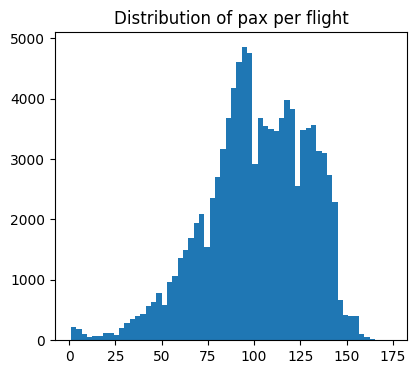

In [7]:
# outliers in pax e luaggage
print(df1[["pax", "seats", "load_factor"]].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95, 0.99]))

plt.figure(figsize=(10,4))
plt.subplot(121)
hist = plt.hist(df1["pax"], bins=60)
plt.title("Distribution of pax per flight")

In [8]:
from xgboost import XGBRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, root_mean_squared_error

def regression_report(y_true, y_pred, title=""):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    mae = mean_absolute_error(y_true, y_pred)
    rmse = root_mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    mask = y_true != 0
    mape = (
        np.mean(
            np.abs(
                (y_true[mask] - y_pred[mask]) / y_true[mask]
            )
        ) * 100
    )

    wape = (
        np.sum(np.abs(y_true - y_pred))
        / np.sum(np.abs(y_true))
        * 100
    )

    print(title)
    print(f"MAE: {mae:.2f}")
    print(f"MAPE: {mape:.2f} %")
    print(f"RMSE: {rmse:.2f}")
    print(f"WAPE: {wape:.2f} %")
    print(f"R2: {r2:.3f}")

In [9]:
def baseline_model(train, val):

    train = train.copy()
    val = val.copy()

    global_lf = train["pax"].mean()

    mean_full = (
        train
        .groupby(["car", "apt", "ac", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt_month = (
        train
        .groupby(["car", "apt", "month"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car_apt = (
        train
        .groupby(["car", "apt"])["pax"]
        .mean()
        .rename("pred_pax")
    )

    mean_car = (
        train
        .groupby("car")["pax"]
        .mean()
        .rename("pred_pax")
    )

    out = val.copy()

    # livello più specifico
    out = out.merge(
        mean_full,
        on=["car", "apt", "ac", "month"],
        how="left"
    )

    # fallback car + apt + month
    fallback = out.merge(
        mean_car_apt_month,
        on=["car", "apt", "month"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback car + apt
    fallback = out.merge(
        mean_car_apt,
        on=["car", "apt"],
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # fallback carrier
    fallback = out.merge(
        mean_car,
        on="car",
        how="left",
        suffixes=("", "_fallback")
    )

    out["pred_pax"] = out["pred_pax"].fillna(
        fallback["pred_pax_fallback"]
    )

    # ultimo fallback: media globale
    out["pred_pax"] = out["pred_pax"].fillna(global_lf)

    return out

In [10]:
# validation 2024 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Validation 2024")

#Baseline Validation 2024
MAE: 13.64
MAPE: 15.62 %
RMSE: 17.88
WAPE: 12.50 %
R2: 0.508


In [11]:
# test 2025 baseline model

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

val_baseline = baseline_model(train, val)

regression_report(val["pax"], val_baseline["pred_pax"], "#Baseline Test 2025")

#Baseline Test 2025
MAE: 14.31
MAPE: 74.57 %
RMSE: 20.84
WAPE: 13.33 %
R2: 0.443


In [12]:
# validation 2024 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2024
val_idx = df["year"] == 2024

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Validation PAX 2024")

# XGBoost Validation PAX 2024
MAE: 12.56
MAPE: 13.71 %
RMSE: 16.36
WAPE: 11.51 %
R2: 0.588


In [13]:
# test 2025 XGBoost 

# split
df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2025
val_idx = df["year"] == 2025

train = df.loc[train_idx].copy()
val = df.loc[val_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
X_val = val[features].copy()

y_train = train[target]
y_val = val[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])
X_val_apt = apt_encoder.transform(X_val[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])
X_val_other = other_encoder.transform(X_val[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

X_val = pd.concat(
    [X_val[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_val_apt, columns=apt_names),
     pd.DataFrame(X_val_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=7,
    subsample=0.5,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

pax_pred_val = xgb_pax.predict(X_val)
pax_pred_val = np.rint(pax_pred_val).astype(int)

regression_report(val["pax"], pax_pred_val, "# XGBoost Test PAX 2025")

# XGBoost Test PAX 2025
MAE: 11.74
MAPE: 17.36 %
RMSE: 15.76
WAPE: 10.93 %
R2: 0.682


<Axes: title={'center': 'Feature importance'}, xlabel='Importance score', ylabel='Features'>

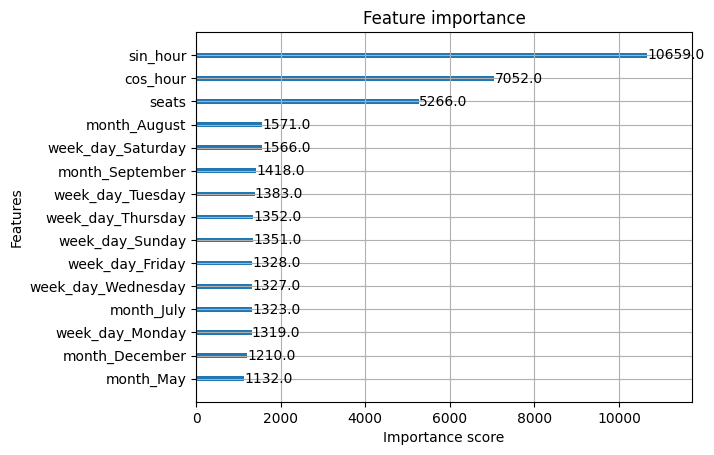

In [14]:
from xgboost import plot_importance
plot_importance(xgb_pax, max_num_features=15)

##### training for production

In [16]:
# training fino al 2025 incluso

df = df1.copy()
df = df.sort_values("fdatetime").copy()

train_idx = df["year"] < 2026
train = df.loc[train_idx].copy()

features = ["month", "week_day", "sin_hour", "cos_hour", "car", "seats", "apt", "ac"]
target = "pax"

apt_column = ["apt"]
other_categorical_columns = ["month", "week_day", "car", "ac"]
numeric_columns = ["sin_hour", "cos_hour", "seats"]

X_train = train[features].copy()
y_train = train[target]

# Airport encoder:
apt_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=50,
    sparse_output=False,
)
# Other categorical variables
other_encoder = OneHotEncoder(
    handle_unknown="infrequent_if_exist",
    min_frequency=100,
    sparse_output=False,
)

# Fit on training data
apt_encoder.fit(X_train[apt_column])
other_encoder.fit(X_train[other_categorical_columns])

# Transform airport
X_train_apt = apt_encoder.transform(X_train[apt_column])

# Transform other categoricals
X_train_other = other_encoder.transform(X_train[other_categorical_columns])

# Column names
apt_names = apt_encoder.get_feature_names_out(apt_column)
other_names = other_encoder.get_feature_names_out(other_categorical_columns)

# Assemble
X_train = pd.concat(
    [X_train[numeric_columns].reset_index(drop=True),
     pd.DataFrame(X_train_apt, columns=apt_names),
     pd.DataFrame(X_train_other, columns=other_names),
    ], axis=1,
)

xgb_pax = XGBRegressor(
    objective="reg:squarederror",
    random_state=10,
    n_estimators=1000,
    learning_rate=0.03,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    n_jobs=-1,
)

xgb_pax.fit(X_train, y_train)

# save model and encoders

import joblib

model_bundle = {
    "model": xgb_pax,
    "apt_encoder": apt_encoder,
    "other_encoder": other_encoder,
    "features": features,
    "apt_column": apt_column,
    "other_categorical_columns": other_categorical_columns,
    "numeric_columns": numeric_columns,
    "target": "pax",
}

joblib.dump(
    model_bundle,
    f"data/pax_model.joblib",
)

['data/pax_model.joblib']

### arrival curves

In [37]:
# entire schedule
apt_iata= 'FLR'

url = f"https://aosnice-api.toscana-aeroporti.com/{apt_iata}/getPlannedFlights"
response = requests.get(url)
response.raise_for_status()
data = response.json()
flights = data["RESPONSE"]["result"]["elements"]

rows = []
for f in flights:
    rows.append({
        "flight_number": f.get("number"),
        "nature": f.get("nature", {}).get("code"),
        "carrier": f.get("carrier", {}).get("publicCode"),
        "airport": f.get("airport", {}).get("code"),
        "periods": f.get("periods", [])
    })

all_flights = pd.DataFrame(rows)

# filter departures and explode periods
sched = all_flights[all_flights["nature"] == "P"].drop(columns=["nature"]).rename(columns={"airport": "apt"}).copy()
sched["periods"] = sched["periods"].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
sched = (
    sched
    .explode("periods", ignore_index=True)
    .join(pd.json_normalize(sched.explode("periods")["periods"]))
    .drop(columns=["periods"])
)

sched["from"] = pd.to_datetime(sched["from"]).dt.normalize()
sched["to"] = pd.to_datetime(sched["to"]).dt.normalize()
sched["flight_number"] = (sched["flight_number"].astype(str).str.replace(r"\.0$", "", regex=True).str.lstrip("0"))
sched["freq"] = sched["frequency"].str.split(",")
sched.to_csv(os.path.join('data', 'schedule_all.csv'), index=False)

In [40]:
# security data
df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')
df_security = df_security[
    (df_security['LAST_POSITION'] == 'SECURITY_AREA') &
    (df_security['PASSAGE_AUTHORIZED'] == 1)
].copy()

df_security["FLIGHT_NUMBER"] = df_security["FLIGHT_NUMBER"].astype(str).str.lstrip("0")
df_security["DATE_OF_FLIGHT"] = pd.to_datetime(df_security["DATE_OF_FLIGHT"]).dt.normalize()
df_security["SCR_TIME"] = pd.to_datetime(df_security["SCR_TIME"], errors="coerce")

df_security = (
    df_security
    .sort_values('SCR_TIME')
    .drop_duplicates(subset='ID', keep='last')
    .reset_index(drop=True)
)

cols_to_keep = ['ID', 'DATE_OF_FLIGHT', 'OPERATING_CARRIER', 'FLIGHT_NUMBER', 'SCR_TIME']
df_security = df_security[cols_to_keep].copy()
df_security["weekday"] = df_security["DATE_OF_FLIGHT"].dt.isocalendar().day

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\4287610874.py:2: DtypeWarning: Columns (5) have mixed types. Specify dtype option on import or set low_memory=False.
  df_security = pd.read_csv(os.path.join('data', 'security_arrivals.csv'), sep=';')


In [42]:
# merge
sched = pd.read_csv(os.path.join('data', 'schedule_all.csv'))
sched['flight_number'] = sched['flight_number'].astype(str)

out = df_security.merge(
    sched,
    left_on=["OPERATING_CARRIER", "FLIGHT_NUMBER"],
    right_on=["carrier", "flight_number"],
    how="left"
).drop(columns=["carrier", "flight_number"])
out["frequency"] = out["frequency"].fillna("")

mask = (
    out["DATE_OF_FLIGHT"].between(out["from"], out["to"])
    &
    out.apply(
        lambda r: str(r["weekday"]) in r["frequency"].split(","),
        axis=1
    )
)

out = out[mask].copy()

out["SCR_TIME"] = pd.to_datetime(out["SCR_TIME"], errors="coerce")
out["time"] = pd.to_datetime(out["time"], errors="coerce")
out['flight_number'] = out['OPERATING_CARRIER'] + ' ' + out['FLIGHT_NUMBER']

out["departure_dt"] = (
    out["DATE_OF_FLIGHT"]
    + pd.to_timedelta(out["time"].dt.hour, unit="h")
    + pd.to_timedelta(out["time"].dt.minute, unit="m")
    + pd.to_timedelta(out["time"].dt.second, unit="s")
)

out["advance"] = (out["departure_dt"] - out["SCR_TIME"]).dt.total_seconds() / 60

out["month"] = out["departure_dt"].dt.month_name(locale="en_US")
out["departure_hour"] = out["departure_dt"].dt.hour
out["time_band"] = pd.cut(
    out["departure_hour"],
    bins=[-1, 5, 9, 13, 17, 21, 23],
    labels=[
        "00-05",
        "06-09",
        "10-13",
        "14-17",
        "18-21",
        "22-23",
    ]
)
out.rename(columns={"OPERATING_CARRIER": "car"}, inplace=True)

out["advance"].describe(percentiles=[0.01, 0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

count    304311.000000
mean        105.636527
std          35.450038
min        -561.066667
1%           30.936667
5%           52.700000
10%          62.983333
25%          81.200000
50%         103.550000
75%         129.083333
90%         154.983333
95%         168.650000
99%         178.700000
max         347.183333
Name: advance, dtype: float64

In [43]:
# clean outliers
p5 = out["advance"].quantile(0.05)
p99 = out["advance"].quantile(0.999)

df_arrivals_clean = out[(out["advance"] <= p99) & (out["advance"] >= p5)].copy()

print(f"soglia p5: {p5:.1f} min")
print(f"soglia p99: {p99:.1f} min")
print("righe totali:", len(out))
print("righe rimosse:", len(out) - len(df_arrivals_clean))
print("righe rimanenti:", len(df_arrivals_clean))

soglia p5: 52.7 min
soglia p99: 201.5 min
righe totali: 304311
righe rimosse: 15512
righe rimanenti: 288799


#### test vari

In [44]:
def advance_summary(df, group_cols, min_count=100):

    summary = (
        df.groupby(group_cols)["advance"]
        .agg(
            count="count",
            mean="mean",
            median="median",
            std="std",
            p05=lambda x: x.quantile(0.05),
            p25=lambda x: x.quantile(0.25),
            p75=lambda x: x.quantile(0.75),
            p95=lambda x: x.quantile(0.95),
        )
        .reset_index()
    )

    summary = summary[
        summary["count"] >= min_count
    ].copy()

    return summary.sort_values(
        "median",
        ascending=False
    )

def plot_boxplot(df, group_col, min_count=100, top_n=20):
    counts = df[group_col].value_counts()

    if isinstance(df[group_col].dtype, pd.CategoricalDtype):
        valid_groups = [
            g for g in df[group_col].cat.categories
            if counts.get(g, 0) >= min_count
        ]
    else:
        valid_groups = counts[counts >= min_count].index.tolist()

    valid_groups = valid_groups[:top_n]

    data = [
        df.loc[df[group_col] == g, "advance"].dropna()
        for g in valid_groups
    ]

    plt.figure(figsize=(12, 6))

    plt.boxplot(
        data,
        tick_labels=valid_groups,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 1,
            "alpha": 0.5,
            "markeredgewidth": 1,
        }
    )

    plt.ylabel("Minutes before departure")
    plt.xlabel(group_col)
    plt.title(f"Security advance by {group_col}")

    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

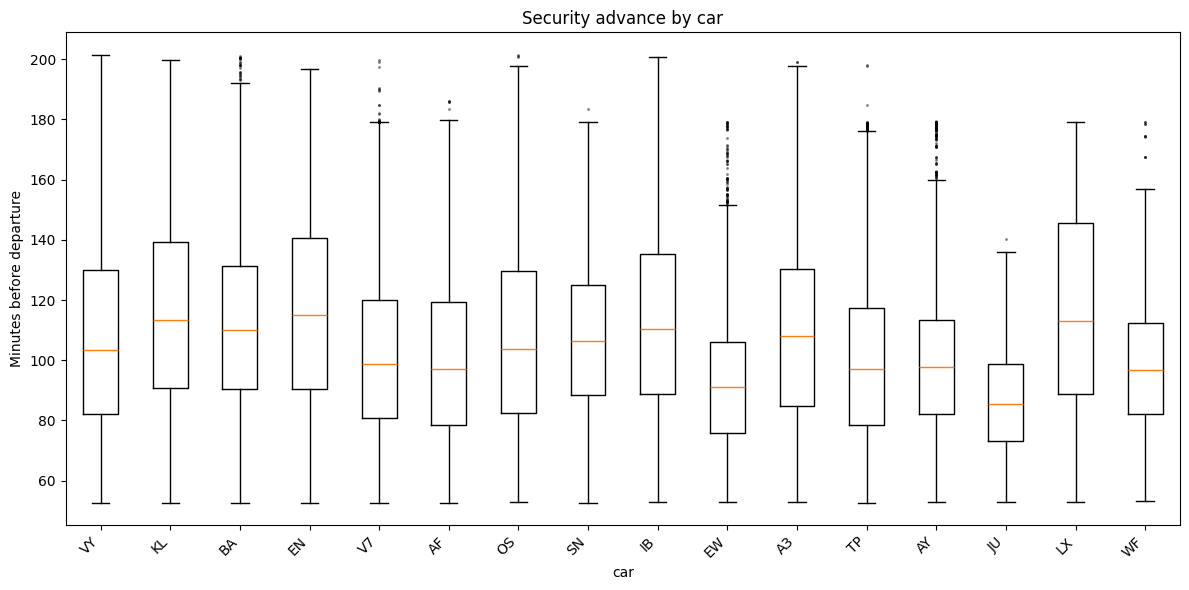

In [45]:
by_carrier = plot_boxplot(
    df_arrivals_clean,
    "car"
)

by_carrier

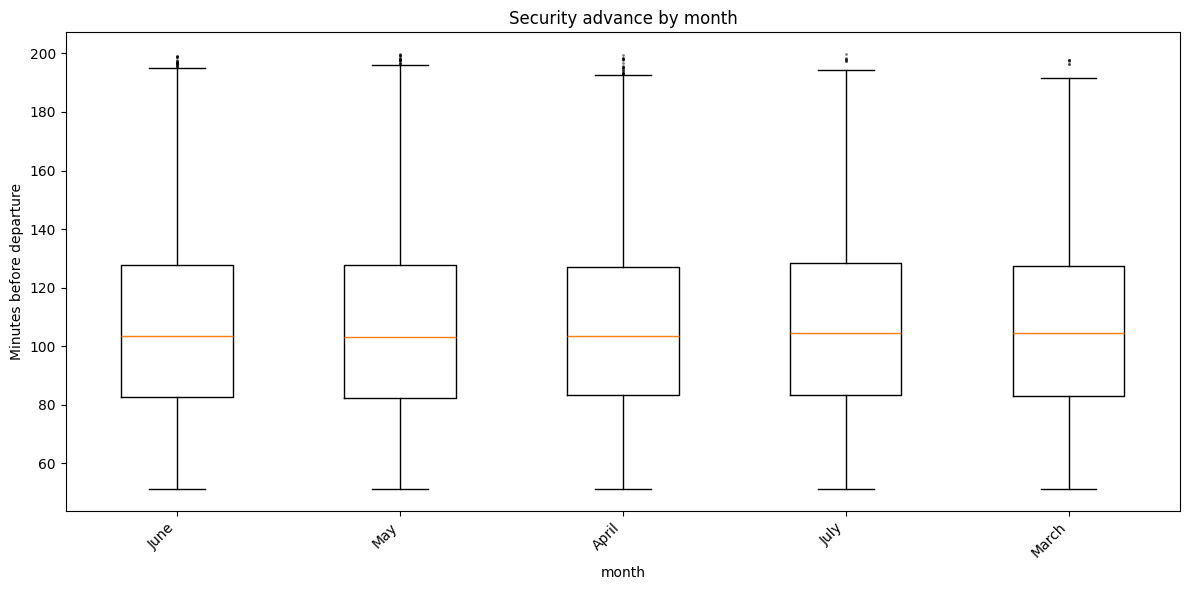

In [85]:
by_month = plot_boxplot(
    df_arrivals_clean,
    "month"
)

by_month

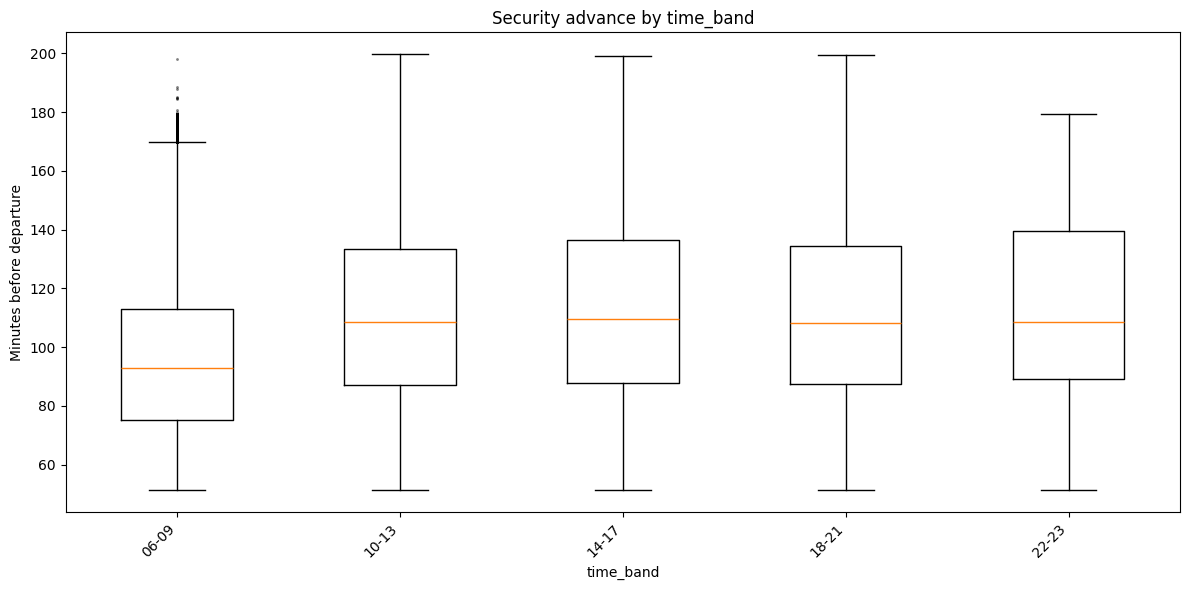

In [86]:
by_time = plot_boxplot(
    df_arrivals_clean,
    "time_band",
    min_count=1
)
by_time

#### normalizing flows

In [46]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import zuko

torch.manual_seed(42)
np.random.seed(42)

df_nf = df_arrivals_clean.copy()
df_nf["log_advance"] = np.log(df_nf["advance"])

cat_cols = ["car", "month", "time_band", "apt"]
MIN_FREQ = 10

code_lookup = {}
cardinalities = {}

for col in cat_cols:
    counts = df_nf[col].value_counts()
    keep = set(counts[counts >= MIN_FREQ].index)
    categories = sorted(keep) + ["UNK"]
    lookup = {cat: i for i, cat in enumerate(categories)}

    df_nf[col + "_code"] = df_nf[col].where(df_nf[col].isin(keep), "UNK").map(lookup)
    code_lookup[col] = lookup
    cardinalities[col] = len(categories)

print("cardinalità (incluso UNK):", cardinalities)

# split per volo
df_nf["flight_key"] = df_nf["flight_number"] + "_" + df_nf["DATE_OF_FLIGHT"].astype(str)

unique_flights = df_nf["flight_key"].unique()
rng = np.random.default_rng(42)
rng.shuffle(unique_flights)

n_val = int(0.15 * len(unique_flights))
val_flights = set(unique_flights[:n_val])
df_nf["is_val"] = df_nf["flight_key"].isin(val_flights)

train_df = df_nf[~df_nf["is_val"]].reset_index(drop=True)
val_df = df_nf[df_nf["is_val"]].reset_index(drop=True)

# standardizzazione log_advance (mean=0, std=1)
log_adv_mean = train_df["log_advance"].mean()
log_adv_std = train_df["log_advance"].std()

train_df["log_advance_std"] = (train_df["log_advance"] - log_adv_mean) / log_adv_std
val_df["log_advance_std"] = (val_df["log_advance"] - log_adv_mean) / log_adv_std

code_cols = [c + "_code" for c in cat_cols]

class AdvanceDataset(Dataset):
    def __init__(self, frame):
        self.y = torch.tensor(frame["log_advance_std"].to_numpy(), dtype=torch.float32).unsqueeze(-1)
        self.cats = torch.tensor(frame[code_cols].to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.y[idx], self.cats[idx]

train_loader = DataLoader(AdvanceDataset(train_df), batch_size=1024, shuffle=True)
val_loader = DataLoader(AdvanceDataset(val_df), batch_size=4096, shuffle=False)

cardinalità (incluso UNK): {'car': 17, 'month': 6, 'time_band': 6, 'apt': 26}


In [47]:
class Embedder(nn.Module):
    def __init__(self, cardinalities, embed_dim=8):
        super().__init__()
        self.embeddings = nn.ModuleList([
            nn.Embedding(card, embed_dim) for card in cardinalities.values()
        ])

    def forward(self, cats):
        parts = [emb(cats[:, i]) for i, emb in enumerate(self.embeddings)]
        return torch.cat(parts, dim=-1)

embed_dim = 8
embedder = Embedder(cardinalities, embed_dim=embed_dim)
context_dim = embed_dim * len(cat_cols)

flow = zuko.flows.NSF(
    features=1,
    context=context_dim,
    transforms=3,
    hidden_features=(64, 64),
)

optimizer = torch.optim.Adam(
    list(embedder.parameters()) + list(flow.parameters()),
    lr=1e-3,
)

def run_epoch(loader, train=True):
    embedder.train(train)
    flow.train(train)
    total_loss, n = 0.0, 0

    for y, cats in loader:
        context = embedder(cats)
        dist = flow(context)
        loss = -dist.log_prob(y).mean()

        if train:
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        total_loss += loss.item() * len(y)
        n += len(y)

    return total_loss / n

best_val = float("inf")
patience, bad_epochs = 8, 0
best_state = None

for epoch in range(200):
    train_nll = run_epoch(train_loader, train=True)
    with torch.no_grad():
        val_nll = run_epoch(val_loader, train=False)

    print(f"epoch {epoch+1:03d}  train NLL {train_nll:.4f}  val NLL {val_nll:.4f}")

    if val_nll < best_val:
        best_val = val_nll
        bad_epochs = 0
        best_state = (
            {k: v.clone() for k, v in embedder.state_dict().items()},
            {k: v.clone() for k, v in flow.state_dict().items()},
        )
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"early stopping all'epoca {epoch+1} (miglior val NLL: {best_val:.4f})")
            break

embedder.load_state_dict(best_state[0])
flow.load_state_dict(best_state[1])

epoch 001  train NLL 1.3169  val NLL 1.2962
epoch 002  train NLL 1.2959  val NLL 1.2985
epoch 003  train NLL 1.2918  val NLL 1.2931
epoch 004  train NLL 1.2881  val NLL 1.2901
epoch 005  train NLL 1.2854  val NLL 1.2937
epoch 006  train NLL 1.2852  val NLL 1.2874
epoch 007  train NLL 1.2834  val NLL 1.2939
epoch 008  train NLL 1.2824  val NLL 1.2904
epoch 009  train NLL 1.2810  val NLL 1.2890
epoch 010  train NLL 1.2803  val NLL 1.2904
epoch 011  train NLL 1.2813  val NLL 1.2889
epoch 012  train NLL 1.2779  val NLL 1.2910
epoch 013  train NLL 1.2786  val NLL 1.2879
epoch 014  train NLL 1.2775  val NLL 1.2900
early stopping all'epoca 14 (miglior val NLL: 1.2874)


<All keys matched successfully>

In [48]:
def encode_value(col, value):
    lookup = code_lookup[col]
    return lookup.get(value, lookup["UNK"])

def sample_advance(car, month, time_band, apt, n_samples=5000):
    codes = [encode_value(c, v) for c, v in zip(cat_cols, [car, month, time_band, apt])]
    cats_tensor = torch.tensor([codes] * n_samples, dtype=torch.long)

    embedder.eval()
    flow.eval()
    with torch.no_grad():
        context = embedder(cats_tensor)
        z_samples = flow(context).sample()

    log_adv_samples = z_samples.squeeze(-1) * log_adv_std + log_adv_mean
    return torch.exp(log_adv_samples).numpy()

#### Validation

C:\Users\zanch\AppData\Local\Temp\ipykernel_21712\3716960570.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()


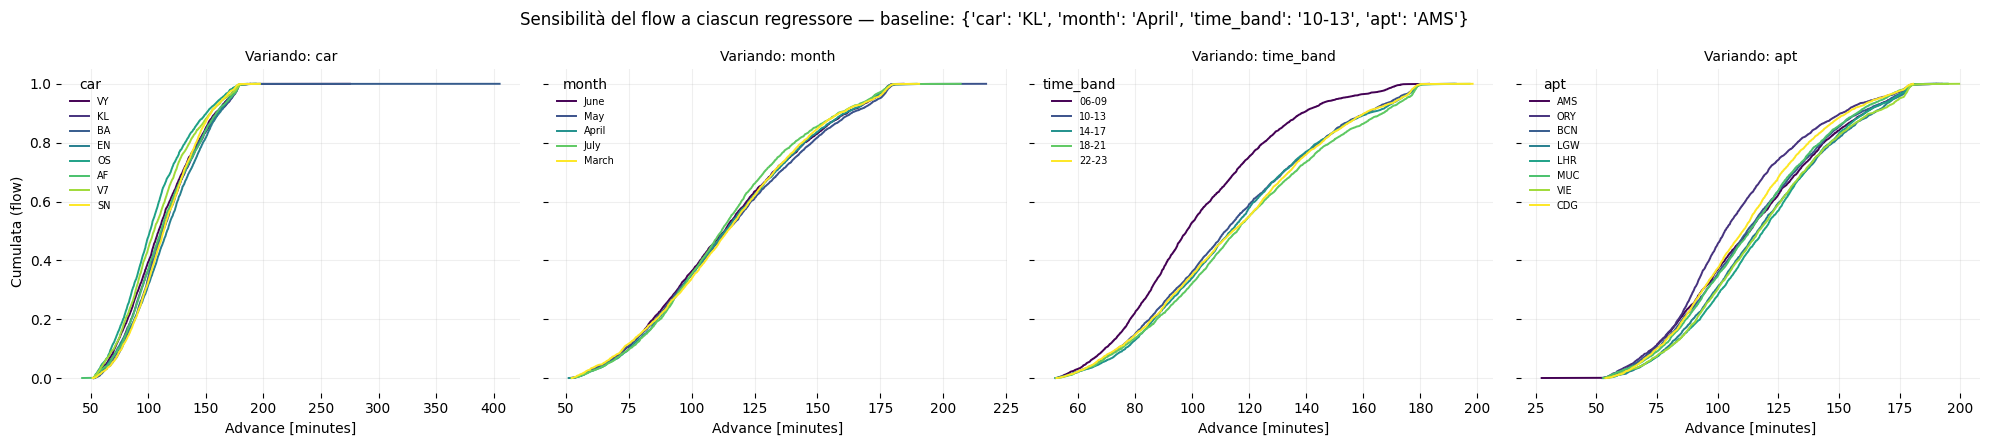

In [51]:
TIME_BAND_ORDER = ["00-05", "06-09", "10-13", "14-17", "18-21", "22-23"]
BASE_COMBO = dict(zip(
    cat_cols,
    train_df.groupby(cat_cols)["flight_key"].nunique().idxmax()
))

TOP_N = 8  # valori più frequenti da confrontare per categoria, altrimenti apt/car sono illeggibili

fig, axes = plt.subplots(1, len(cat_cols), figsize=(5 * len(cat_cols), 4.5), sharey=True)

for ax, cat in zip(axes, cat_cols):
    if cat == "time_band":
        top_values = [v for v in TIME_BAND_ORDER if v in train_df["time_band"].unique()]
    else:
        top_values = (
            train_df.groupby(cat)["flight_key"].nunique()
            .sort_values(ascending=False)
            .head(TOP_N)
            .index
        )

    colors = plt.cm.viridis(np.linspace(0, 1, len(top_values)))

    for value, color in zip(top_values, colors):
        combo = {**BASE_COMBO, cat: value}
        sampled = sample_advance(combo["car"], combo["month"], combo["time_band"], combo["apt"], n_samples=3000)
        s = np.sort(sampled)
        ax.plot(s, np.arange(1, len(s) + 1) / len(s), color=color, linewidth=1.4, label=str(value))

    ax.set_title(f"Variando: {cat}", fontsize=10)
    ax.set_xlabel("Advance [minutes]")
    ax.grid(alpha=0.2)
    ax.legend(frameon=False, fontsize=7, title=cat)
    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_ylabel("Cumulata (flow)")
fig.suptitle(f"Sensibilità del flow a ciascun regressore — baseline: {BASE_COMBO}")
plt.tight_layout()

#### save for production

In [52]:
torch.save({
    "embedder_state": embedder.state_dict(),
    "flow_state": flow.state_dict(),
    "code_lookup": code_lookup,
    "cardinalities": cardinalities,
    "cat_cols": cat_cols,
    "log_adv_mean": log_adv_mean,
    "log_adv_std": log_adv_std,
    "embed_dim": embed_dim,
    "transforms": 3,
    "hidden_features": (64, 64),
}, f"data/arrival_flow.pt")

### Allocation

#### single funcs

In [2]:
def _synthetic_day(seed, T=96):
    rng = np.random.default_rng(seed)
    t = np.arange(T)
    lam = np.full(T, 0.5)                           # baseline: pax / 15 min
    for _ in range(rng.integers(1, 7)):             # 1-2 peaks
        center, width, height = rng.uniform(10, T - 10), rng.uniform(4, 9), rng.uniform(6, 30)
        lam += height * np.exp(-0.5 * ((t - center) / width) ** 2)
    return rng.poisson(lam).astype(int).tolist()

arrivals = _synthetic_day(seed=1)

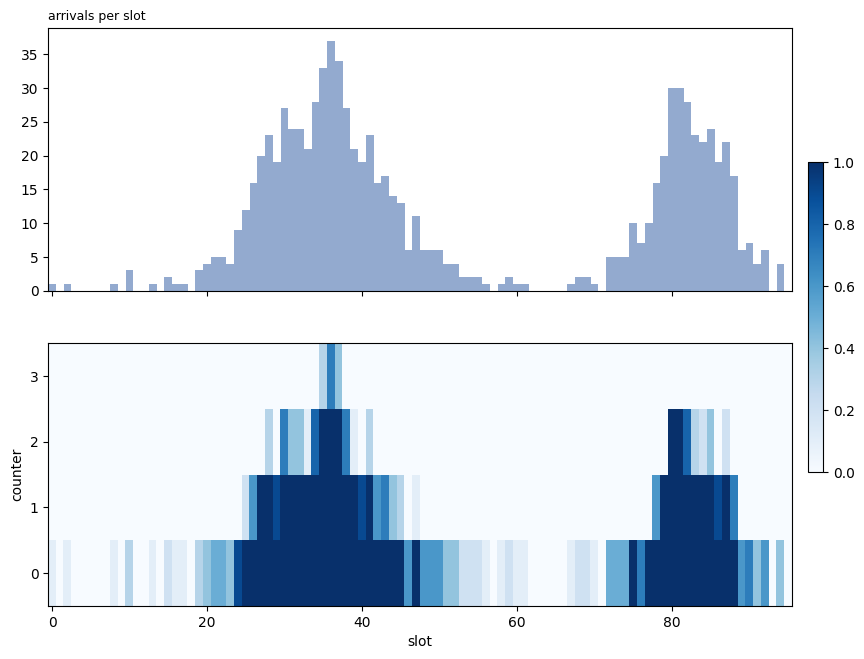

In [3]:
def arrivals_to_demand_grid(arrivals, mean_processing_rate, unit_time, freq_minutes=15):
    """
    arrivals             : (T,) pax arriving in each slot
    mean_processing_rate : pax per hour processed by one counter
    unit_time            : time unit for the processing rate
    returns D
        D              : (n_counters, T) float in [0, 1]; row c = c-th counter
    """
    a = np.asarray(arrivals, dtype=np.float64)
    if a.ndim != 1:
        raise ValueError("arrivals must be 1-D (T,)")
    if mean_processing_rate <= 0 or freq_minutes <= 0:
        raise ValueError("mean_processing_rate and freq_minutes must be > 0")
    pax_per_counter_bin = mean_processing_rate * (freq_minutes / unit_time)
    required_exact = a / pax_per_counter_bin                       # counters needed, float
    n_counters = int(np.ceil(required_exact.max()))
    if n_counters == 0:
        raise ValueError("no arrivals: the demand grid would be empty")
    layers = np.arange(n_counters)[:, None]                        # counter index 0..n-1
    D = np.clip(required_exact[None, :] - layers, 0.0, 1.0)        # (n_counters, T)
    return D

def plot_grid(arrivals, D):
    T = D.shape[1]
    x = np.arange(T)
    fig, axes = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1]})
    axes[0].bar(x, arrivals, width=1.0, color="#4C72B0", alpha=0.6)
    axes[0].set_title("arrivals per slot", fontsize=9, loc="left")
    im = axes[1].imshow(D, aspect="auto", origin="lower", cmap="Blues", vmin=0, vmax=1,
                        extent=[-0.5, T - 0.5, -0.5, D.shape[0] - 0.5], interpolation="nearest")
    axes[1].set_yticks(range(D.shape[0]))
    axes[1].set_ylabel("counter")
    axes[1].set_xlabel("slot")
    fig.colorbar(im, ax=axes, fraction=0.02, pad=0.02)
    plt.show()

MEAN_PROCESSING_RATE = 10

D = arrivals_to_demand_grid(arrivals, MEAN_PROCESSING_RATE, unit_time=15)
plot_grid(arrivals, D)

In [4]:
L, alpha = 12, 0.2
curve = solve_coverage_batch(D, L, alpha, return_curve=True)

K_total = 20
g = allocate_budget(curve, K_total)

sols = solve_allocated(D, L, alpha, g)

print(f"{'ctr':>3} {'k':>3} {'value':>8} | {'inside':>7} {'outside':>8} {'missed':>7}")
for i, s in enumerate(sols):
    assert abs(s.value - (s.inside - alpha * s.outside)) < 1e-9          # objective identity
    assert abs(s.inside + s.missed - D[i].sum()) < 1e-9                  # all demand is served or missed
    print(f"{i:>3} {g.k[i]:>3} {s.value:>8.2f} | {s.inside:>7.2f} {s.outside:>8.2f} {s.missed:>7.2f}")

ctr   k    value |  inside  outside  missed
  0   5    43.80 |   46.50    13.50    2.50
  1   3    26.28 |   27.90     8.10    0.00
  2   2     7.68 |   10.40    13.60    0.30
  3   0     0.00 |    0.00     0.00    1.40


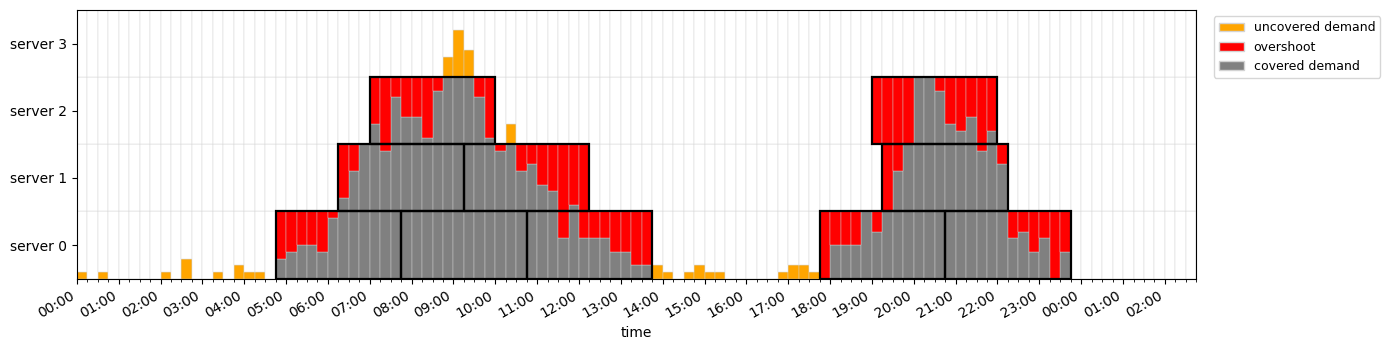

In [5]:
def plot_grid_overlay(grid, alloc, time_values, L=None):

    import matplotlib.dates as mdates
    from matplotlib.patches import Patch, Rectangle

    D = np.asarray(grid, dtype=np.float64)
    if isinstance(alloc, (list, tuple)):                     # list of Solution
        cov = np.vstack([np.asarray(s.coverage, dtype=bool) for s in alloc])
    else:                                                    # bool matrix (n_rows, T)
        cov = np.asarray(alloc, dtype=bool)
    if cov.shape[0] != D.shape[0] or cov.shape[1] < D.shape[1]:
        raise ValueError(f"alloc shape {cov.shape} incompatible with grid shape {D.shape}")
    real_bins = D.shape[1]
    extra = cov.shape[1] - real_bins                         # overhang slots after the end of the day
    if extra:
        D = np.pad(D, ((0, 0), (0, extra)))

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape

    bin_minutes = (
        (time_values.iloc[1] - time_values.iloc[0]).total_seconds() / 60
        if len(time_values) > 1 else 15
    )

    if extra and len(time_values) == real_bins:              # extend the time axis over the overhang
        more = time_values.iloc[-1] + pd.to_timedelta(np.arange(1, extra + 1) * bin_minutes, unit="min")
        time_values = pd.concat([time_values, pd.Series(more)], ignore_index=True)
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")

    time_values = pd.to_datetime(pd.Series(time_values).reset_index(drop=True))
    n_rows, n_bins = D.shape
    if len(time_values) != n_bins:
        raise ValueError(f"time_values has {len(time_values)} entries, grid has {n_bins} columns")

    x0 = mdates.date2num(time_values)                        # left edge of each bin
    width = bin_minutes / (24 * 60)                          # bin width in matplotlib date units
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)

    fig, ax = plt.subplots(figsize=(14, 0.4 * n_rows + 2))
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        # bottom part: demand  (grey if covered, orange if not)
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        # top part: capacity not needed  (red if covered = waste, white if not)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)

    # outlined rectangle per shift block
    if isinstance(alloc, (list, tuple)) and L is not None:
        blocks = [(c, int(s0), int(L)) for c, sol in enumerate(alloc) for s0 in sol.starts]

    for c, s0, ln in blocks:
        ax.add_patch(Rectangle((x0[s0], c), ln * width, 1, fill=False,
                               edgecolor="black", linewidth=1.6, zorder=3))
        
    ax.set_xlim(x0[0], x0[-1] + width)
    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([f"server {y}" for y in range(n_rows)])

    ax.xaxis_date()
    ax.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax.set_xlabel("time")

    legend_handles = [
        Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered demand"),
        Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
        Patch(facecolor=GREY, edgecolor="lightgray", label="covered demand"),
    ]
    ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()

time_values = pd.date_range("2026-01-01 00:00", periods=D.shape[1], freq=f"15min")
plot_grid_overlay(D, sols, time_values, L=L)

In [6]:
rep = coverage_report(D, sols, L, time_values)

rep.total

n_blocks          10.000000
demand            89.000000
covered_demand    84.800000
missed_demand      4.200000
idle_capacity     35.200000
coverage           0.952809
dtype: float64

#### class and synthetic arrivals

In [2]:
def make_synthetic_arrivals(
    pax_per_server_bin: float,
    peak_servers=(4.2, 3.4),
    peak_hours=(8.0, 17.5),
    widths_h=(1.6, 2.0),
    base_servers=0.15,
    day="2026-03-02",
    bin_minutes=15,
    seed=0,
) -> pd.Series:
    T = 24 * 60 // bin_minutes
    t_h = (np.arange(T) + 0.5) * bin_minutes / 60                      # centro del bin, in ore
    servers_needed = np.full(T, base_servers)
    for hour, width, amp in zip(peak_hours, widths_h, peak_servers):
        servers_needed += amp * np.exp(-0.5 * ((t_h - hour) / width) ** 2)
    rng = np.random.default_rng(seed)
    index = pd.date_range(day, periods=T, freq=f"{bin_minutes}min")
    return pd.Series(rng.poisson(servers_needed * pax_per_server_bin).astype(float),
                     index=index, name="arrivals")

BIN_MINUTES = 15
arrivals = make_synthetic_arrivals(20, seed=1)

registry={
    1: {'label': '1', 'processing_rate': 10, 'processing_unit': 10, 'priority': 5},
    2: {'label': '2', 'processing_rate': 10, 'processing_unit': 10, 'priority': 5},
    3: {'label': '3', 'processing_rate': 10, 'processing_unit': 10, 'priority': 5},
    4: {'label': '4', 'processing_rate': 10, 'processing_unit': 10, 'priority': 5},
    5: {'label': '5', 'processing_rate': 10, 'processing_unit': 10, 'priority': 5},
    6: {'label': '6', 'processing_rate': 2, 'processing_unit': 10, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

arrivals

2026-03-02 00:00:00    4.0
2026-03-02 00:15:00    4.0
2026-03-02 00:30:00    4.0
2026-03-02 00:45:00    2.0
2026-03-02 01:00:00    2.0
                      ... 
2026-03-02 22:45:00    1.0
2026-03-02 23:00:00    4.0
2026-03-02 23:15:00    5.0
2026-03-02 23:30:00    3.0
2026-03-02 23:45:00    3.0
Freq: 15min, Name: arrivals, Length: 96, dtype: float64

In [17]:
planner = security_class.SecurityLanePlanner(arrivals, server_registry)

res = planner.run(L=3, alpha=0.5, K_total=1000)

2026-10-09 11:10:09,657 | WARNING | app.services.security_class | [SecurityLanePlanner] demand needs up to 8 servers but the registry has 6: the demand of the upper 2 row(s) (3.15 counter-bins) cannot be served.


alpha=1.90  total coverage=0.918


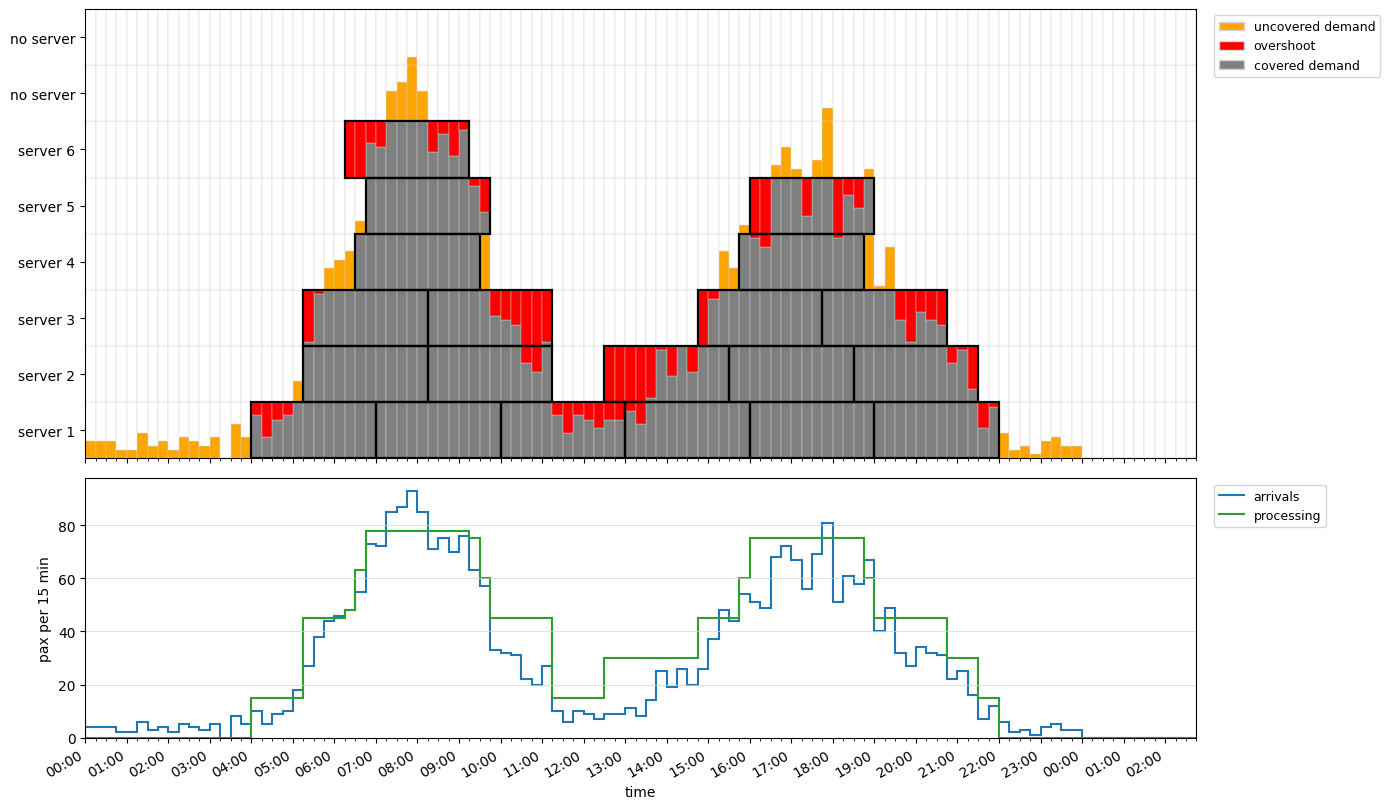

In [18]:
def _coverage_from_results(res):
    """
    Rebuild, from the planner results only, what the plot needs:
        D           (n_rows, n_bins) demand grid padded with zeros over the overhang bins
        cov         (n_rows, n_bins) bool, bins covered by a shift (from server_schedule)
        blocks      [(row, start, end), ...] one per shift (datetimes)
        time_values pd.Series of bin starts (day + overhang), from df_curves
    """
    time_values = pd.to_datetime(res.df_curves["time"]).reset_index(drop=True)
    D = np.asarray(res.demand_grid, dtype=np.float64)
    extra = len(time_values) - D.shape[1]                       # bins after the end of the day
    if extra < 0:
        raise ValueError("df_curves is shorter than demand_grid")
    D = np.pad(D, ((0, 0), (0, extra)))
 
    row_of = {label: c for c, label in enumerate(res.server_labels)}
    cov = np.zeros(D.shape, dtype=bool)
    blocks = []
    for label, intervals in res.server_schedule.items():
        if label not in row_of:
            raise ValueError(f"schedule has server {label!r} that is not in server_labels")
        c = row_of[label]
        for start, end in intervals:
            in_shift = (time_values >= pd.Timestamp(start)) & (time_values < pd.Timestamp(end))
            cov[c] |= in_shift.to_numpy()
            blocks.append((c, start, end))
    return D, cov, blocks, time_values
 
def plot_grid_overlay(res):
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch, Rectangle
 
    D, cov, blocks, time_values = _coverage_from_results(res)
    n_rows, n_bins = D.shape
 
    x0 = mdates.date2num(time_values)                          # left edge of each bin
    width = res.bin_minutes / (24 * 60)                        # bin width in matplotlib date units
    x_edges = np.append(x0, x0[-1] + width)                    # bin edges, for the step curves
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)
 
    # top: demand vs allocation per server; bottom: arrivals vs processing per bin (same x axis)
    fig, (ax, ax_curves) = plt.subplots(
        2, 1, figsize=(14, 0.4 * n_rows + 5), sharex=True,
        gridspec_kw={"height_ratios": [0.4 * n_rows + 2, 3]},
    )
 
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)
 
    for c, start, end in blocks:
        xs, xe = mdates.date2num(start), mdates.date2num(end)
        ax.add_patch(Rectangle((xs, c), (xe - xs), 1, fill=False,
                               edgecolor="black", linewidth=1.6, zorder=3))
 
    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([
        f"server {res.server_labels[c]}" if c < len(res.server_labels) else "no server"
        for c in range(n_rows)
    ])
    ax.legend(
        handles=[
            Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered demand"),
            Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
            Patch(facecolor=GREY, edgecolor="lightgray", label="covered demand"),
        ],
        loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9,
    )
 
    # bottom panel: step curves straight from df_curves (pax per bin)
    ax_curves.stairs(res.df_curves["demand"].to_numpy(), x_edges, color="tab:blue", linewidth=1.5, label="arrivals")
    ax_curves.stairs(res.df_curves["processing"].to_numpy(), x_edges, color="tab:green", linewidth=1.5, label="processing")
    ax_curves.set_ylim(bottom=0)
    ax_curves.set_ylabel(f"pax per {res.bin_minutes:g} min")
    ax_curves.grid(axis="y", color="lightgray", linewidth=0.5)
    ax_curves.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
 
    ax_curves.set_xlim(x0[0], x0[-1] + width)
    ax_curves.xaxis_date()
    ax_curves.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax_curves.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_curves.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax_curves.set_xlabel("time")
 
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()
print(f"alpha={alpha:.2f}  total coverage={planner.report.total.coverage:.3f}")
plot_grid_overlay(res)

In [9]:
results= pd.DataFrame()

for alpha in np.arange(0.0, 2, 0.1):
    res = planner.run(L=4, alpha=alpha, K_total=1000)
    print(f"alpha={alpha:.2f}  total coverage={planner.report.total.coverage:.3f}")
    row={
        "alpha": alpha,
        "coverage": planner.report.total.coverage,
    }
    results = pd.concat([results, pd.DataFrame([row])], ignore_index=True)

results

2026-10-09 11:09:08,254 | WARNING | app.services.security_class | [SecurityLanePlanner] demand needs up to 8 servers but the registry has 6: the demand of the upper 2 row(s) (3.15 counter-bins) cannot be served.
2026-10-09 11:09:08,261 | WARNING | app.services.security_class | [SecurityLanePlanner] demand needs up to 8 servers but the registry has 6: the demand of the upper 2 row(s) (3.15 counter-bins) cannot be served.
2026-10-09 11:09:08,267 | WARNING | app.services.security_class | [SecurityLanePlanner] demand needs up to 8 servers but the registry has 6: the demand of the upper 2 row(s) (3.15 counter-bins) cannot be served.
2026-10-09 11:09:08,272 | WARNING | app.services.security_class | [SecurityLanePlanner] demand needs up to 8 servers but the registry has 6: the demand of the upper 2 row(s) (3.15 counter-bins) cannot be served.
2026-10-09 11:09:08,279 | WARNING | app.services.security_class | [SecurityLanePlanner] demand needs up to 8 servers but the registry has 6: the demand 

alpha=0.00  total coverage=0.986
alpha=0.10  total coverage=0.983
alpha=0.20  total coverage=0.962
alpha=0.30  total coverage=0.962
alpha=0.40  total coverage=0.927
alpha=0.50  total coverage=0.927
alpha=0.60  total coverage=0.927
alpha=0.70  total coverage=0.927
alpha=0.80  total coverage=0.927
alpha=0.90  total coverage=0.927
alpha=1.00  total coverage=0.826
alpha=1.10  total coverage=0.789
alpha=1.20  total coverage=0.789
alpha=1.30  total coverage=0.789
alpha=1.40  total coverage=0.789
alpha=1.50  total coverage=0.789
alpha=1.60  total coverage=0.789
alpha=1.70  total coverage=0.789
alpha=1.80  total coverage=0.789
alpha=1.90  total coverage=0.789


,alpha,coverage
0,0.0,0.986050
1,0.1,0.982987
2,0.2,0.961552
3,0.3,0.961552
4,0.4,0.926846
5,0.5,0.926846
6,0.6,0.926846
7,0.7,0.926846
8,0.8,0.926846
9,0.9,0.926846


#### with flights

In [2]:
date=dt.datetime(2026, 6, 1)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()
schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)
arrivals= security_class.expected_arrivals(flight_demand)

registry={
    1: {'label': '1', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    2: {'label': '2', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    3: {'label': '3', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    4: {'label': '4', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    5: {'label': '5', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    6: {'label': '6', 'processing_rate': 50, 'processing_unit': 15, 'priority': 5},
    }
server_registry = preprocessing.build_processing_params_by_server(registry)

2026-10-09 12:09:57,447 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.


In [3]:
planner = security_class.SecurityLanePlanner(arrivals, server_registry)

res = planner.run(L=3, alpha=0.9, K_total=1000)

alpha=0.90  total coverage=0.820


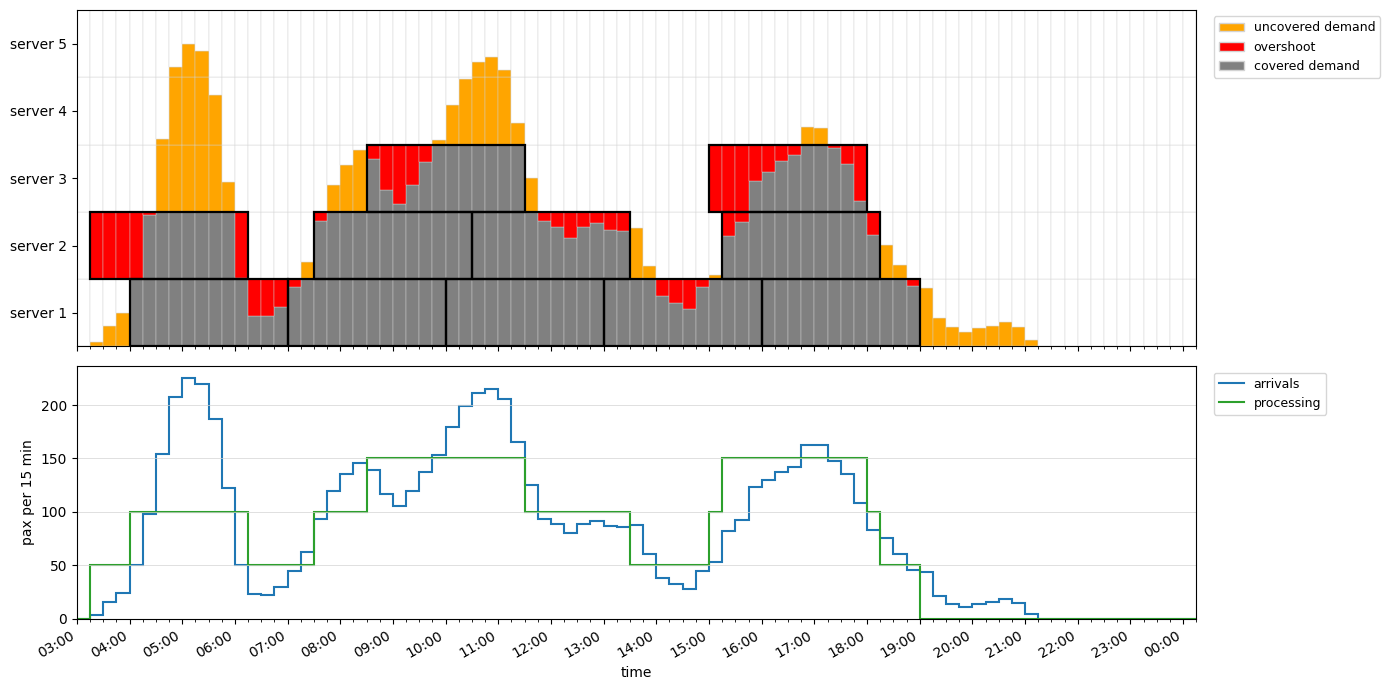

In [4]:
def _coverage_from_results(res):
    """
    Rebuild, from the planner results only, what the plot needs:
        D           (n_rows, n_bins) demand grid padded with zeros over the overhang bins
        cov         (n_rows, n_bins) bool, bins covered by a shift (from server_schedule)
        blocks      [(row, start, end), ...] one per shift (datetimes)
        time_values pd.Series of bin starts (day + overhang), from df_curves
    """
    time_values = pd.to_datetime(res.df_curves["time"]).reset_index(drop=True)
    D = np.asarray(res.demand_grid, dtype=np.float64)
    extra = len(time_values) - D.shape[1]                       # bins after the end of the day
    if extra < 0:
        raise ValueError("df_curves is shorter than demand_grid")
    D = np.pad(D, ((0, 0), (0, extra)))
 
    row_of = {label: c for c, label in enumerate(res.server_labels)}
    cov = np.zeros(D.shape, dtype=bool)
    blocks = []
    for label, intervals in res.server_schedule.items():
        if label not in row_of:
            raise ValueError(f"schedule has server {label!r} that is not in server_labels")
        c = row_of[label]
        for start, end in intervals:
            in_shift = (time_values >= pd.Timestamp(start)) & (time_values < pd.Timestamp(end))
            cov[c] |= in_shift.to_numpy()
            blocks.append((c, start, end))
    return D, cov, blocks, time_values
 
def plot_grid_overlay(res):
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt
    from matplotlib.patches import Patch, Rectangle
 
    D, cov, blocks, time_values = _coverage_from_results(res)
    n_rows, n_bins = D.shape
 
    x0 = mdates.date2num(time_values)                          # left edge of each bin
    width = res.bin_minutes / (24 * 60)                        # bin width in matplotlib date units
    x_edges = np.append(x0, x0[-1] + width)                    # bin edges, for the step curves
    GREY, ORANGE, RED, WHITE = "grey", "orange", "red", "white"
    edge = dict(edgecolor="lightgray", linewidth=0.3)
 
    # top: demand vs allocation per server; bottom: arrivals vs processing per bin (same x axis)
    fig, (ax, ax_curves) = plt.subplots(
        2, 1, figsize=(14, 0.4 * n_rows + 5), sharex=True,
        gridspec_kw={"height_ratios": [0.4 * n_rows + 2, 3]},
    )
 
    for c in range(n_rows):
        d, covered = D[c], cov[c]
        m = d > 1e-9
        ax.bar(x0[m], d[m], width=width, bottom=c, align="edge",
               color=np.where(covered[m], GREY, ORANGE), **edge)
        idle = 1.0 - d
        m = idle > 1e-9
        ax.bar(x0[m], idle[m], width=width, bottom=c + d[m], align="edge",
               color=np.where(covered[m], RED, WHITE), **edge)
 
    for c, start, end in blocks:
        xs, xe = mdates.date2num(start), mdates.date2num(end)
        ax.add_patch(Rectangle((xs, c), (xe - xs), 1, fill=False,
                               edgecolor="black", linewidth=1.6, zorder=3))
 
    ax.set_ylim(0, n_rows)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels([
        f"server {res.server_labels[c]}" if c < len(res.server_labels) else "no server"
        for c in range(n_rows)
    ])
    ax.legend(
        handles=[
            Patch(facecolor=ORANGE, edgecolor="lightgray", label="uncovered demand"),
            Patch(facecolor=RED, edgecolor="lightgray", label="overshoot"),
            Patch(facecolor=GREY, edgecolor="lightgray", label="covered demand"),
        ],
        loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9,
    )
 
    # bottom panel: step curves straight from df_curves (pax per bin)
    ax_curves.stairs(res.df_curves["demand"].to_numpy(), x_edges, color="tab:blue", linewidth=1.5, label="arrivals")
    ax_curves.stairs(res.df_curves["processing"].to_numpy(), x_edges, color="tab:green", linewidth=1.5, label="processing")
    ax_curves.set_ylim(bottom=0)
    ax_curves.set_ylabel(f"pax per {res.bin_minutes:g} min")
    ax_curves.grid(axis="y", color="lightgray", linewidth=0.5)
    ax_curves.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
 
    ax_curves.set_xlim(x0[0], x0[-1] + width)
    ax_curves.xaxis_date()
    ax_curves.xaxis.set_major_locator(mdates.HourLocator(interval=1))
    ax_curves.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    ax_curves.xaxis.set_minor_locator(mdates.MinuteLocator(byminute=[0, 15, 30, 45]))
    ax_curves.set_xlabel("time")
 
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()
print(f"alpha={res.alpha:.2f}  total coverage={planner.report.total.coverage:.3f}")
plot_grid_overlay(res)

#### add simulation

2026-10-09 12:11:07,045 | INFO | app.services.security_class | [SecuritySimulator] Launching pool: 10 total tasks, 4 workers


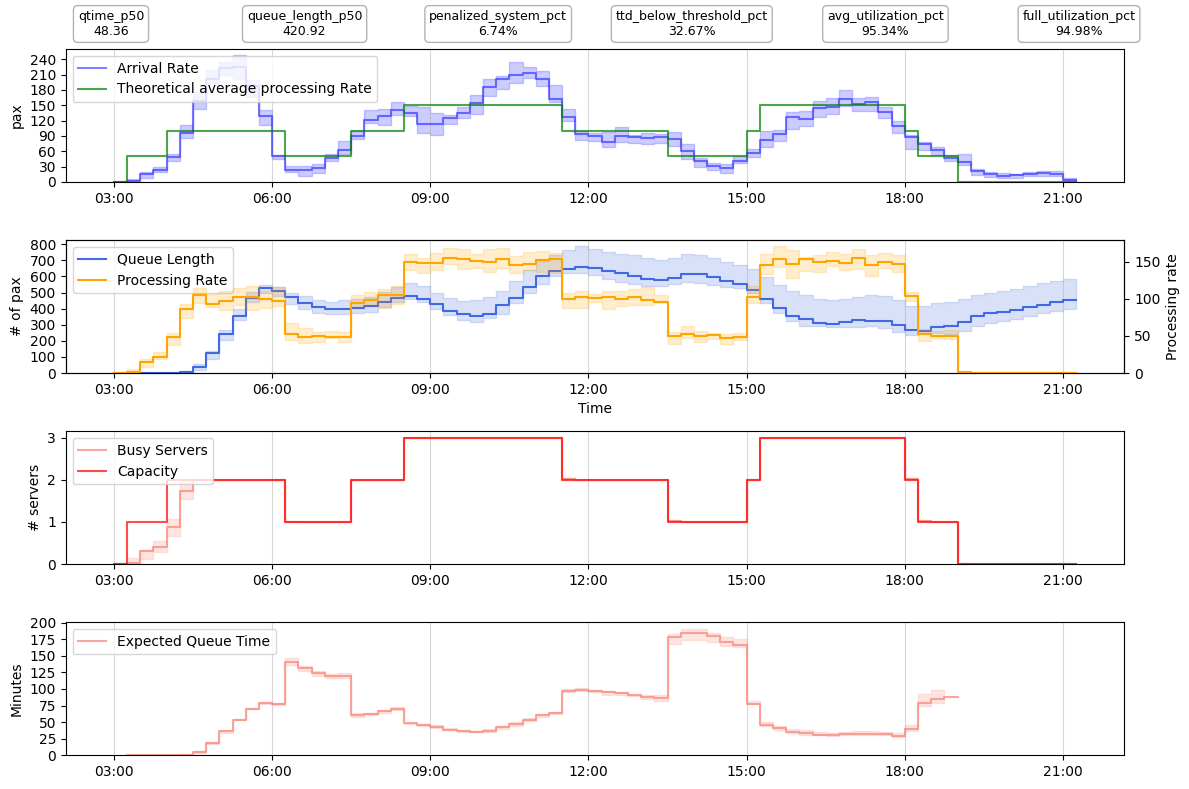

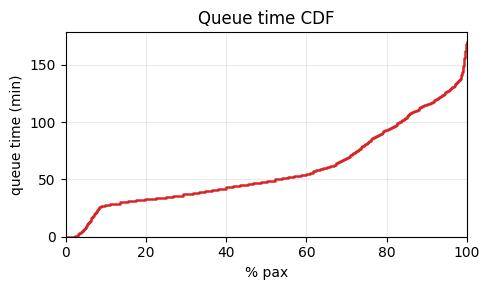

In [6]:
classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand,
    intervals=utils.server_schedule_to_intervals(res.server_schedule),
    server_registry=server_registry)

sim_results = classe2.run(n_scenarios=10, n_workers=4, timebin=15, buffer_threshold=30, base_seed=base_seed)
plotutils.plot_all(sim_results.df_timeline, sim_results.df_kpis)
plotutils.plot_queue_cdf(sim_results.df_queue_cdf)

### Opt + Sim

#### simple sim

In [23]:
import random as rand
import dataclasses

intervals=[Interval(start=dt.datetime(2024, 6, 1, 10, 0), end=dt.datetime(2024, 6, 1, 11, 0), server_labels=('1a',)),
           Interval(start=dt.datetime(2024, 6, 1, 11, 0), end=dt.datetime(2024, 6, 1, 12, 0), server_labels=()),
           Interval(start=dt.datetime(2024, 6, 1, 12, 0), end=dt.datetime(2024, 6, 1, 15, 0), server_labels=('1a','1b')),
          ]

flights=[Flight(flight_key='f1', flight_number="f1", departure_dt=dt.datetime(2024, 6, 1, 13, 0), pax_segments={'standard': 150})]
all_pax = [Passenger(id=f"pax_{i}", flight_key='f1', segment="standard", flight_number="f1", flight_departure_dt=dt.datetime(2024, 6, 1, 13, 0), arrival_dt=dt.datetime(2024, 6, 1, 9, 0)) 
           for i in range(11)
        ]

all_pax.append(Passenger(id=f"pax_{11}", flight_key='f1', segment="standard", flight_number="f1", flight_departure_dt=dt.datetime(2024, 6, 1, 13, 0), arrival_dt=dt.datetime(2024, 6, 1, 11, 1)))

simulation_start_dt = min(min(p.arrival_dt for p in all_pax), intervals[0].start)
# convert datetime to minutes since simulation_start_dt
all_pax = [dataclasses.replace(
        p,
        arrival_min=(p.arrival_dt - simulation_start_dt).total_seconds() / 60,
        flight_departure_min=(
        p.flight_departure_dt - simulation_start_dt
        ).total_seconds() / 60,
)
for p in all_pax
]

registry={
    1: {'label': '1a', 'processing_rate': 1, 'processing_unit': 1},
    2: {'label': '1b', 'processing_rate': 1, 'processing_unit': 1},
    3: {'label': '2', 'processing_rate': 1, 'processing_unit': 1},}
server_registry = build_processing_params_by_server(registry)

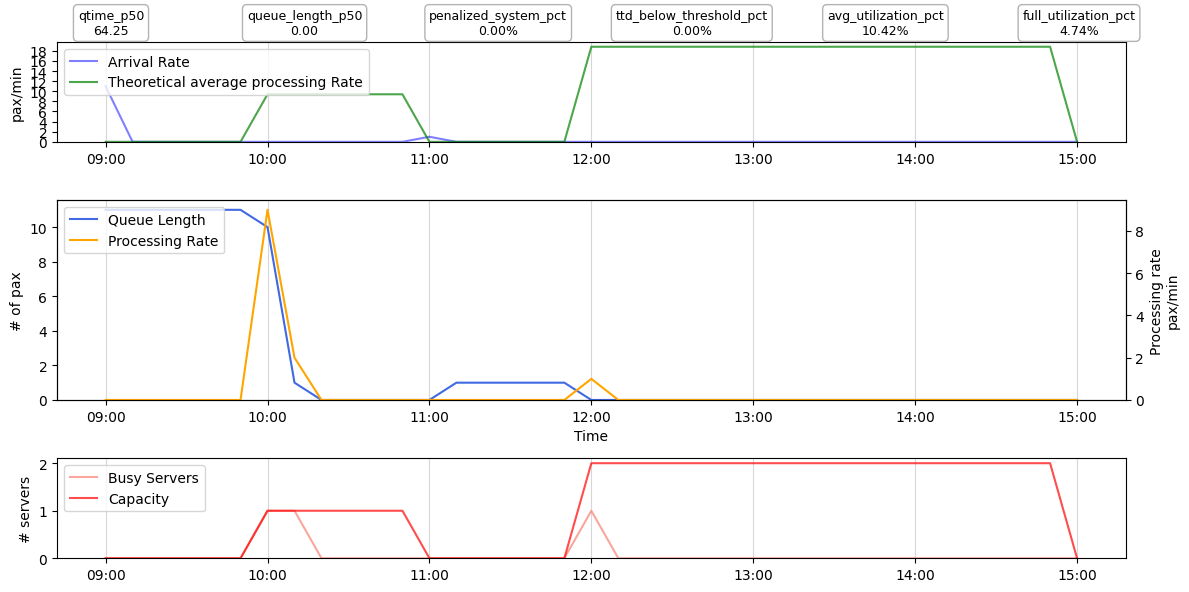

,id,segment,flight_number,flight_departure_dt,arrival_dt,processing_time,server_id,start_dt,end_dt,queue_time,time_to_departure,served
0,pax_0,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,1.064536,1a,2024-06-01 10:00:00.000000,2024-06-01 10:01:03.872151,60.000000,178.935464,True
1,pax_1,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,1.219267,1a,2024-06-01 10:01:03.872151,2024-06-01 10:02:17.028198,61.064536,177.716197,True
2,pax_2,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,0.478103,1a,2024-06-01 10:02:17.028198,2024-06-01 10:02:45.714368,62.283803,177.238094,True
3,pax_3,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,1.006961,1a,2024-06-01 10:02:45.714368,2024-06-01 10:03:46.132036,62.761906,176.231133,True
4,pax_4,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,0.961452,1a,2024-06-01 10:03:46.132036,2024-06-01 10:04:43.819179,63.768867,175.269680,True
5,pax_5,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,1.266671,1a,2024-06-01 10:04:43.819179,2024-06-01 10:05:59.819424,64.730320,174.003010,True
6,pax_6,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,0.987342,1a,2024-06-01 10:05:59.819424,2024-06-01 10:06:59.059952,65.996990,173.015667,True
7,pax_7,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,1.119428,1a,2024-06-01 10:06:59.059952,2024-06-01 10:08:06.225659,66.984333,171.896239,True
8,pax_8,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,1.085908,1a,2024-06-01 10:08:06.225659,2024-06-01 10:09:11.380154,68.103761,170.810331,True
9,pax_9,standard,f1,2024-06-01 13:00:00,2024-06-01 09:00:00,1.266318,1a,2024-06-01 10:09:11.380154,2024-06-01 10:10:27.359232,69.189669,169.544013,True


In [25]:
sim = simulation.QueueSimulationSinglequeue(all_pax=all_pax, intervals=intervals, server_registry=server_registry, start_dt=simulation_start_dt, seed=base_seed)
results= sim.run()

df_timeline = metrics.get_df_timeline(results, timebin=10)

kpis = metrics.get_kpis(results, df_timeline=df_timeline, buffer_threshold=30)

df_pax = metrics.get_df_pax(results.pax_data, simulation_start_dt=simulation_start_dt)
plotutils.plot_all(df_timeline, pd.DataFrame([kpis]))
df_pax

In [7]:
metrics.get_df_server(df_pax=df_pax, intervals=intervals)

,server_id,available_minutes,served_pax,busy_minutes,mean_processing_time,first_service_start,last_service_end,idle_minutes,utilization_pct
0,1a,240.0,12,12.765077,1.063756,2024-06-01 10:00:00,2024-06-01 12:01:23.926027,227.234923,5.318782
1,1b,180.0,0,0.000000,NaN,NaT,NaT,180.000000,0.000000


In [8]:
metrics.get_df_server_detailed(df_pax=df_pax, intervals=intervals)

,server_id,start_dt,end_dt,duration_minutes,status,scheduled,busy,pax_id,flight_key,segment,processing_time
0,1a,2024-06-01 09:00:00.000000,2024-06-01 10:00:00.000000,60.000000,closed,False,False,None,None,None,NaN
1,1a,2024-06-01 10:00:00.000000,2024-06-01 10:01:03.872151,1.064536,busy,True,True,pax_0,None,standard,1.064536
2,1a,2024-06-01 10:01:03.872151,2024-06-01 10:02:17.028198,1.219267,busy,True,True,pax_1,None,standard,1.219267
3,1a,2024-06-01 10:02:17.028198,2024-06-01 10:02:45.714368,0.478103,busy,True,True,pax_2,None,standard,0.478103
4,1a,2024-06-01 10:02:45.714368,2024-06-01 10:03:46.132036,1.006961,busy,True,True,pax_3,None,standard,1.006961
5,1a,2024-06-01 10:03:46.132036,2024-06-01 10:04:43.819179,0.961452,busy,True,True,pax_4,None,standard,0.961452
6,1a,2024-06-01 10:04:43.819179,2024-06-01 10:05:59.819424,1.266671,busy,True,True,pax_5,None,standard,1.266671
7,1a,2024-06-01 10:05:59.819424,2024-06-01 10:06:59.059952,0.987342,busy,True,True,pax_6,None,standard,0.987342
8,1a,2024-06-01 10:06:59.059952,2024-06-01 10:08:06.225659,1.119428,busy,True,True,pax_7,None,standard,1.119428
9,1a,2024-06-01 10:08:06.225659,2024-06-01 10:09:11.380154,1.085908,busy,True,True,pax_8,None,standard,1.085908


#### run

In [2]:
date=dt.datetime(2026, 6, 1)

schedule_or= pd.read_excel(os.path.join('data', 'schedule.xlsx'))
schedule_std= preprocessing.preprocess_schedule_FLR(schedule_or, profile_specs={})
schedule_f = schedule_std[schedule_std["date"] == date].copy()
schedule_pred = predictive.predict_pax(df=schedule_f, path=f"data/pax_model.joblib")
schedule_pred

,date,schtime,car,apt,ac,seats,dir,fdate,fdatetime,nflt,flight_type,pax_standard
3929,2026-06-01,0615,V7,CTA,319,156,out,2026-06-01,2026-06-01 06:15:00,V7 1705,standard,137
3930,2026-06-01,0625,AZ,FCO,319,144,out,2026-06-01,2026-06-01 06:25:00,AZ 1676,standard,123
3931,2026-06-01,0630,LX,ZRH,290,110,out,2026-06-01,2026-06-01 06:30:00,LX 1683,standard,95
3932,2026-06-01,0630,EN,FRA,E95,120,out,2026-06-01,2026-06-01 06:30:00,EN 8861,standard,98
3933,2026-06-01,0630,KL,AMS,295,136,out,2026-06-01,2026-06-01 06:30:00,KL 1650,standard,121
...,...,...,...,...,...,...,...,...,...,...,...,...
3986,2026-06-01,1945,LX,ZRH,221,125,out,2026-06-01,2026-06-01 19:45:00,LX 1681,standard,83
3987,2026-06-01,1955,SK,CPH,32N,180,out,2026-06-01,2026-06-01 19:55:00,SK 2964,standard,122
3988,2026-06-01,2015,JU,BEG,AT7,72,out,2026-06-01,2026-06-01 20:15:00,JU 469,standard,56
3989,2026-06-01,2035,AF,CDG,BCS3,148,out,2026-06-01,2026-06-01 20:35:00,AF 1767,standard,116


2026-10-07 17:23:59,773 | WARNING | app.services.preprocessing | More than 10% of flights (12/62) fall back to the unknown arrival sampler. Check the arrival model coverage.
2026-10-07 17:23:59,850 | INFO | app.services.security_class | [SecurityLanePlanner] Launching  optimization: L=2, scale=1, alpha=0.2


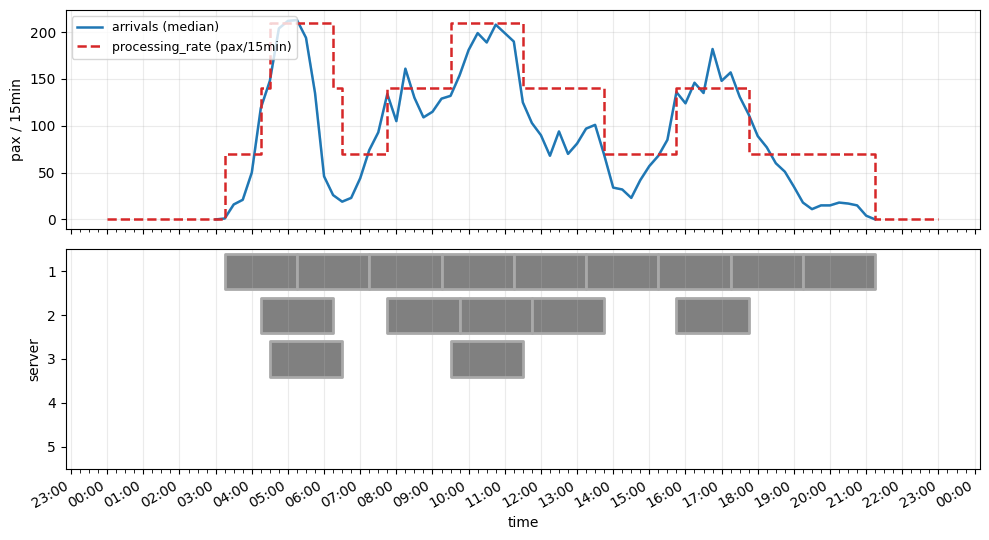

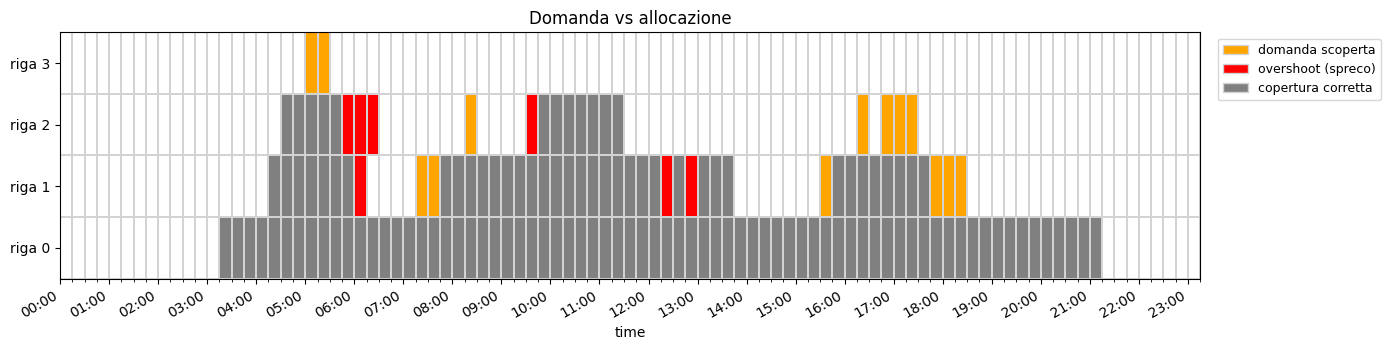

In [3]:
arrival_model = arrival_flow.load_arrival_flow(os.path.join("data", "arrival_flow.pt"))

flight_demand = preprocessing.build_flight_demand(schedule_pred, arrival_model=arrival_model)

flight_groups = {}

for flight in flight_demand:
    day = flight.departure_dt.date().isoformat()

    flight_groups.setdefault(day, []).append(flight)

date=list(flight_groups.keys())[0]

flight_demand_d = flight_groups[date]

registry={
    1: {'label': '1', 'processing_rate': 70, 'processing_unit': 15, 'priority': 1},
    2: {'label': '2', 'processing_rate': 70, 'processing_unit': 15, 'priority': 1},
    3: {'label': '3', 'processing_rate': 70, 'processing_unit': 15, 'priority': 1},
    4: {'label': '4', 'processing_rate': 70, 'processing_unit': 15, 'priority': 1},
    5: {'label': '5', 'processing_rate': 70, 'processing_unit': 15, 'priority': 1},
    }
registry_std = preprocessing.build_processing_params_by_server(registry)

classe= security_class.SecurityLanePlanner(
    flight_demand=flight_demand_d,
    server_registry=registry_std)

L= 2
scale=1
alpha=0.2
opt_results=classe.run(n_scenarios=1, L=L, scale=scale, alpha=alpha, base_seed=base_seed)
plotutils.plot_opt_results(classe.df_requirements, classe.df_arrivals, classe.server_schedule, registry_std)
plotutils.plot_grid_overlay(
    grid=classe.lanes_optimizer.grid,
    rectangles=classe.df_alloc.to_dict("records"),
    time_values=classe.df_requirements["time"],
)

2026-09-24 11:12:18,142 | INFO | app.compute_service.domain.security_class | [SecuritySimulator] Launching pool: 30 total tasks, 4 workers


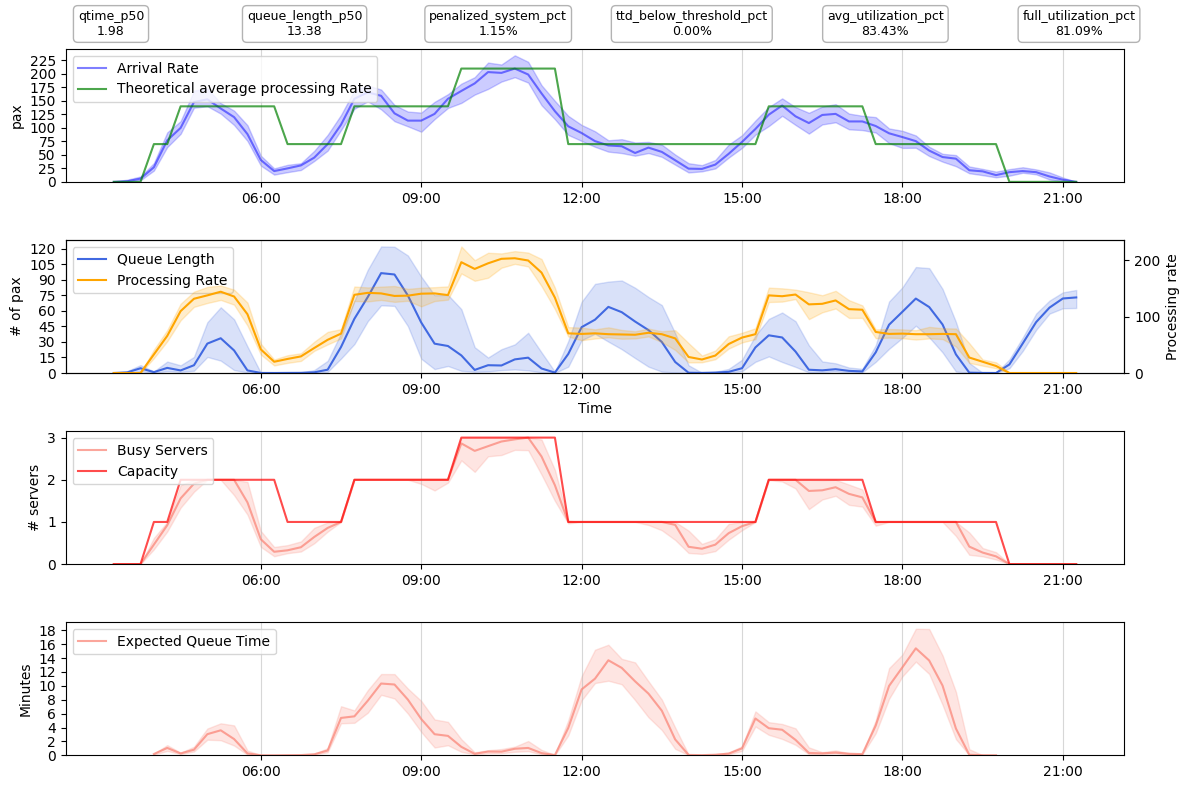

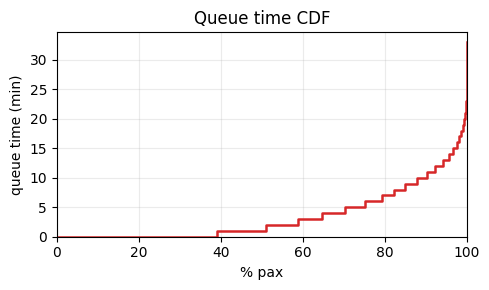

In [11]:
classe2= security_class.SecuritySimulator(
    flight_demand=flight_demand_d,
    intervals=utils.server_schedule_to_intervals(classe.server_schedule),
    server_registry=registry_std)

sim_results = classe2.run(n_scenarios=30, n_workers=4, timebin=15, buffer_threshold=30, base_seed=base_seed)
plotutils.plot_all(sim_results.df_timeline, sim_results.df_kpis)
plotutils.plot_queue_cdf(sim_results.df_queue_cdf)

In [9]:
sim_results.df_kpis

,date,base_seed,n_scenarios,qtime_p5,qtime_p25,qtime_p50,qtime_p75,qtime_p95,qtime_mean,n_arrived,...,n_unserved,penalized_system_pct,ttd_below_threshold_pct,queue_length_p5,queue_length_p25,queue_length_p50,queue_length_p75,queue_length_p95,avg_utilization_pct,full_utilization_pct
0,2026-09-07,42,30,0.0,0.0,0.0,0.164494,0.868028,0.157908,10525.0,...,0.7,0.008234,0.036741,0.0,0.012902,0.249437,1.26355,5.887439,57.935878,35.157545


In [9]:
sim_results.df_timeline

,date,base_seed,n_scenarios,time_bin,arrival_rate_mean,arrival_rate_median,arrival_rate_p5,arrival_rate_p25,arrival_rate_p75,arrival_rate_p95,...,expected_qtime_min_p75,expected_qtime_min_p95,utilization_median_pct,utilization_p5_pct,utilization_p25_pct,utilization_p75_pct,utilization_p95_pct,capacity,service_rate,theoretical_processing_rate
0,2026-09-07,42,30,2026-09-07 01:00:00,0.066667,0.0,0.00,0.00,0.00,0.55,...,NaN,NaN,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0
1,2026-09-07,42,30,2026-09-07 01:15:00,0.466667,0.0,0.00,0.00,1.00,1.55,...,NaN,NaN,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0
2,2026-09-07,42,30,2026-09-07 01:30:00,0.933333,1.0,0.00,0.00,1.75,3.00,...,NaN,NaN,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0
3,2026-09-07,42,30,2026-09-07 01:45:00,0.733333,1.0,0.00,0.00,1.00,2.55,...,0.013157,0.022556,4.712339,0.0,2.021673,6.177906,8.673827,1.0,3.333333,50.0
4,2026-09-07,42,30,2026-09-07 02:00:00,1.166667,1.0,0.00,0.00,2.00,3.00,...,0.000000,0.000000,2.128520,0.0,0.000000,3.858945,6.088563,1.0,3.333333,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
80,2026-09-07,42,30,2026-09-07 21:00:00,64.433333,65.0,54.90,62.00,68.50,70.55,...,64.004570,67.612177,100.000000,100.0,100.000000,100.000000,100.000000,1.0,3.333333,50.0
81,2026-09-07,42,30,2026-09-07 21:15:00,34.633333,35.0,25.45,30.50,38.00,43.20,...,64.233088,67.793310,100.000000,100.0,100.000000,100.000000,100.000000,1.0,3.333333,50.0
82,2026-09-07,42,30,2026-09-07 21:30:00,13.100000,13.0,6.90,11.25,15.00,18.00,...,56.009138,58.753147,100.000000,100.0,100.000000,100.000000,100.000000,1.0,3.333333,50.0
83,2026-09-07,42,30,2026-09-07 21:45:00,0.700000,1.0,0.00,0.00,1.00,2.00,...,NaN,NaN,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.0


In [11]:
sim_results.df_pax

,date,base_seed,n_scenarios,scenario_id,simulation_start_dt,id,segment,flight_number,flight_departure_dt,arrival_dt,processing_time,server_id,start_dt,end_dt,queue_time,time_to_departure,served
0,2026-09-07,42,30,1,2026-09-07 01:00:00,FR6256_202609070610_standard_74,standard,FR 6256,2026-09-07 06:10:00,2026-09-07 01:27:41.907478,0.319361,1a,2026-09-07 01:45:00.000000,2026-09-07 01:45:19.161645,17.301542,264.680639,True
1,2026-09-07,42,30,1,2026-09-07 01:00:00,FR6256_202609070610_standard_5,standard,FR 6256,2026-09-07 06:10:00,2026-09-07 01:28:26.981103,0.365780,1a,2026-09-07 01:45:19.161645,2026-09-07 01:45:41.108459,16.869676,264.314859,True
2,2026-09-07,42,30,1,2026-09-07 01:00:00,FR1491_202609070605_standard_67,standard,FR 1491,2026-09-07 06:05:00,2026-09-07 01:33:45.830434,0.143431,1a,2026-09-07 01:45:41.108459,2026-09-07 01:45:49.714311,11.921300,259.171428,True
3,2026-09-07,42,30,1,2026-09-07 01:00:00,FR589_202609070620_standard_86,standard,FR 589,2026-09-07 06:20:00,2026-09-07 02:03:05.853194,0.302088,1a,2026-09-07 02:03:05.853194,2026-09-07 02:03:23.978494,0.000000,256.600358,True
4,2026-09-07,42,30,1,2026-09-07 01:00:00,FR9851_202609070600_standard_117,standard,FR 9851,2026-09-07 06:00:00,2026-09-07 02:08:24.686473,0.288436,1a,2026-09-07 02:08:24.686473,2026-09-07 02:08:41.992616,0.000000,231.300123,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315745,2026-09-07,42,30,30,2026-09-07 01:00:00,RGN7859_202609072215_standard_5,standard,RGN 7859,2026-09-07 22:15:00,2026-09-07 21:36:50.556874,NaN,None,NaT,NaT,NaN,NaN,False
315746,2026-09-07,42,30,30,2026-09-07 01:00:00,QY7840_202609072220_standard_48,standard,QY 7840,2026-09-07 22:20:00,2026-09-07 21:38:55.396704,NaN,None,NaT,NaT,NaN,NaN,False
315747,2026-09-07,42,30,30,2026-09-07 01:00:00,FR7146_202609072215_standard_91,standard,FR 7146,2026-09-07 22:15:00,2026-09-07 21:40:20.381794,NaN,None,NaT,NaT,NaN,NaN,False
315748,2026-09-07,42,30,30,2026-09-07 01:00:00,QY7840_202609072220_standard_64,standard,QY 7840,2026-09-07 22:20:00,2026-09-07 21:41:12.945923,NaN,None,NaT,NaT,NaN,NaN,False
